## Setup & Dependencies

In [ ]:
# Install required packages
!pip -q install kaggle datasets huggingface_hub google-cloud-storage matplotlib seaborn wordcloud

In [ ]:
# Core imports
import os
import glob
import re
import random
import json
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from IPython.display import display, HTML, Markdown

from datasets import load_dataset, Dataset, concatenate_datasets
from huggingface_hub import hf_hub_download

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("All imports successful!")

All imports successful!


In [ ]:
# Kaggle authentication (upload your kaggle.json)
from google.colab import files, auth

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)

# Check if kaggle.json already exists
kaggle_path = os.path.expanduser("~/.kaggle/kaggle.json")
if not os.path.exists(kaggle_path):
    print("Please upload your kaggle.json file:")
    uploaded = files.upload()
    assert "kaggle.json" in uploaded, "Please upload kaggle.json from your Kaggle account page."
    with open(kaggle_path, "wb") as f:
        f.write(uploaded["kaggle.json"])
    os.chmod(kaggle_path, 0o600)
    print("Kaggle credentials installed!")
else:
    print("Kaggle credentials already present!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Kaggle credentials installed!


In [ ]:
# GCP Authentication
auth.authenticate_user()
print("GCP authentication successful!")

# GCP Configuration
PROJECT_ID = "msda-llm-finetuning"
REGION = "us-central1"
RAW_BUCKET = "msda-llm-raw-data"

# Set project
!gcloud config set project {PROJECT_ID} --quiet
print(f"GCP Project set to: {PROJECT_ID}")

GCP authentication successful!
Updated property [core/project].
GCP Project set to: msda-llm-finetuning


In [ ]:
# Create data directories
DATA_DIR = "./data"
RAW_DIR = f"{DATA_DIR}/raw"
THEORY_DIR = f"{RAW_DIR}/theory"
CODE_DIR = f"{RAW_DIR}/code"
MATH_DIR = f"{RAW_DIR}/math"

for d in [DATA_DIR, RAW_DIR, THEORY_DIR, CODE_DIR, MATH_DIR]:
    os.makedirs(d, exist_ok=True)

print("Directory structure created!")

Directory structure created!


## Helper Functions

In [ ]:
def show_random_samples(df: pd.DataFrame, n: int = 10, title: str = ""):
    """Display n random samples from a DataFrame."""
    if title:
        display(HTML(f"<h4>{title}</h4>"))
    n = min(len(df), n)
    if n > 0:
        with pd.option_context('display.max_colwidth', 200):
            sample_df = df.sample(n, random_state=42)
            display(HTML(sample_df.to_html(index=False)))
    else:
        print("(No data to display)")

def dataset_info(name: str, df: pd.DataFrame, category: str):
    """Print dataset information summary."""
    print(f"\n{'='*60}")
    print(f"{name}")
    print(f"   Category: {category}")
    print(f"   Rows: {len(df):,}")
    print(f"   Columns: {list(df.columns)}")
    print(f"{'='*60}")

def save_dataset(df: pd.DataFrame, name: str, directory: str) -> str:
    """Save dataset to parquet format."""
    filepath = f"{directory}/{name}.parquet"
    df.to_parquet(filepath, index=False)
    print(f"   Saved: {filepath} ({len(df):,} rows)")
    return filepath

def upload_to_gcs(local_path: str, bucket: str, gcs_path: str):
    """Upload file to GCS bucket."""
    gcs_uri = f"gs://{bucket}/{gcs_path}"
    !gsutil -q cp {local_path} {gcs_uri}
    print(f"    Uploaded: {gcs_uri}")
    return gcs_uri

In [ ]:
# ============================================================
# FILTERING FUNCTIONS (from original notebook)
# ============================================================

# --- CodeAlpaca DS Filter ---
CODE_DS_KEYWORDS = [
    r"\b(pandas|numpy|np\.|pd\.)\b",
    r"\b(sklearn|scikit-learn|StandardScaler|LogisticRegression|RandomForest|XGBoost|xgboost)\b",
    r"\b(matplotlib|seaborn|plt\.|plotly|bokeh)\b",
    r"\b(statsmodels|ARIMA|SARIMAX|ols|anova|p\-value|t\-test|chi\-square)\b",
    r"\b(tensorflow|keras|pytorch|torch|nn\.|cnn|rnn|lstm|resnet|transformer)\b",
    r"\b(dataframe|data frame|csv|etl|feature engineering|feature[- ]?selection|cross[- ]?validation)\b",
    r"\b(sql|sqlite|join|group by|window function)\b",
]
CODE_DS_PATTERN = re.compile("|".join(CODE_DS_KEYWORDS), flags=re.IGNORECASE)

def is_ds_code(example: dict) -> bool:
    """Check if CodeAlpaca example is DS-related."""
    blob = " ".join(str(example.get(k, "")) for k in ["instruction", "input", "output"])
    return bool(CODE_DS_PATTERN.search(blob))

# --- Math DS Filter ---
MATH_DS_KEYWORDS = [
    # Statistics / Probability
    r"\bmean\b", r"\bmedian\b", r"\bmode\b", r"\bvariance\b", r"\bstandard deviation\b", r"\bstd\b",
    r"\bexpected value\b", r"\bexpectation\b", r"\bE\[", r"\bP\(", r"\bprobability\b", r"\bdistribution\b",
    r"\bnormal\b", r"\bgaussian\b", r"\bbernoulli\b", r"\bbinomial\b", r"\bpoisson\b", r"\buniform\b",
    r"\bhypothesis test\b", r"\bp[- ]?value\b", r"\bconfidence interval\b", r"\bregression\b",
    r"\blinear regression\b", r"\blogistic regression\b", r"\bcorrelation\b", r"\bpearson\b", r"\bcoefficient\b",
    r"\bchi[- ]?square\b", r"\bt[- ]?test\b", r"\bANOVA\b", r"\bMSE\b", r"\bRMSE\b", r"\bMAPE\b",
    # Linear algebra / Optimization (ML-centric)
    r"\bmatrix\b", r"\bvector\b", r"\beigenvalue\b", r"\beigenvector\b", r"\bsingular value\b",
    r"\bSVD\b", r"\bPCA\b", r"\bgradient\b", r"\bgradient descent\b", r"\bSGD\b", r"\bconvex\b", r"\bLagrange\b",
    r"\bregularization\b", r"\bL1\b", r"\bL2\b", r"\bridge\b",
    # Calculus for ML
    r"\bderivative\b", r"\bpartial derivative\b", r"\bjacobian\b", r"\bhessian\b",
    # DS / wrangling flavored math
    r"\bz[- ]?score\b", r"\bstandardize\b", r"\bnormalize\b", r"\bquantile\b", r"\bpercentile\b",
    r"\bAUC\b", r"\bROC\b", r"\bprecision\b", r"\brecall\b", r"\bf1[- ]?score\b",
]

# Anti-keywords to downweight pure geometry/K-12 word problems
MATH_ANTI_KEYWORDS = [
    r"\btriangle\b", r"\bpolygon\b", r"\bcircle\b", r"\bradius\b", r"\bperimeter\b", r"\brectangle\b",
    r"\btrain leaves\b", r"\bboat\b", r"\bpipe\b", r"\bladder\b",
]

MATH_DS_PATTERN = re.compile("|".join(MATH_DS_KEYWORDS), flags=re.IGNORECASE)
MATH_ANTI_PATTERN = re.compile("|".join(MATH_ANTI_KEYWORDS), flags=re.IGNORECASE)

# Category nudges for MathQA
LIKELY_DS_CATEGORIES = set([
    "probability", "statistics", "data", "algebra", "matrices", "rates",
    "profit_and_loss", "simple_interest", "compound_interest"
])

def text_join(*parts) -> str:
    """Join text parts for filtering."""
    return " | ".join([p for p in parts if isinstance(p, str) and p.strip()])

def is_ds_math(text: str) -> bool:
    """Check if math text is DS-related."""
    if not text:
        return False
    if MATH_ANTI_PATTERN.search(text):
        # Require multiple DS hits if geometry-like
        hits = len(MATH_DS_PATTERN.findall(text))
        return hits >= 2
    return bool(MATH_DS_PATTERN.search(text))

def filter_numina(example: dict) -> bool:
    """Filter NuminaMath-CoT for DS relevance."""
    txt = text_join(example.get("problem", ""), example.get("solution", ""))
    return is_ds_math(txt)

def filter_mathqa(example: dict) -> bool:
    """Filter MathQA for DS relevance."""
    txt = text_join(example.get("Problem", ""), example.get("Rationale", ""))
    hit = is_ds_math(txt)
    cat = (example.get("category") or "").strip().lower()
    if cat in LIKELY_DS_CATEGORIES:
        hit = True
    return hit

def filter_aqua(example: dict) -> bool:
    """Filter AQuA-RAT for DS relevance."""
    txt = text_join(example.get("question", ""), example.get("rationale", ""))
    return is_ds_math(txt)

print("Filter functions defined!")

Filter functions defined!


## THEORY DATASETS

In [ ]:
# Storage for all datasets
all_datasets = {
    "theory": {},
    "code": {},
    "math": {}
}

print("Starting Theory Dataset Loading...\n")

Starting Theory Dataset Loading...



### 1. 1000 Data Science Concepts (Kaggle)

In [ ]:
# Dataset 1: 1000 Data Science Concepts
print("Loading: 1000 Data Science Concepts...")

!kaggle datasets download -d hserdaraltan/1000-data-science-concepts -p {DATA_DIR} -q
!unzip -o {DATA_DIR}/1000-data-science-concepts.zip -d {DATA_DIR} > /dev/null

df_ds_concepts = pd.read_csv(f"{DATA_DIR}/data_science_concepts.csv")
dataset_info("1000 Data Science Concepts", df_ds_concepts, "Theory")

all_datasets["theory"]["ds_concepts"] = df_ds_concepts
show_random_samples(df_ds_concepts, 5, "Sample: DS Concepts")

Loading: 1000 Data Science Concepts...
Dataset URL: https://www.kaggle.com/datasets/hserdaraltan/1000-data-science-concepts
License(s): CC-BY-SA-4.0

1000 Data Science Concepts
   Category: Theory
   Rows: 1,070
   Columns: ['Question', 'Answer']


Question,Answer
"What is Negative Indexing, its purpose, and provide an example.","Negative indexing in Python allows you to count backwards from the end of a list or other sequence types, making it convenient to access elements without needing to know the sequence's length. For example, -1 refers to the last item, -2 to the second last, and so on."
What is a matrix?,"A matrix is a structured arrangement of data elements organized into rows and columns. Each element occupies a specific position within the matrix, defined by its row and column indices. Matrices are fundamental mathematical objects used to represent and manipulate structured data, such as numerical values, coefficients, or observations. They find applications in various fields, including mathematics, physics, computer science, and data analysis, where organizing and processing data in tabular form facilitates computational operations, transformations, and analyses. Matrices serve as foundational structures in linear algebra and are essential for solving systems of equations, performing transformations, and conducting statistical analyses."
Describe the purpose and functioning of ensemble methods in machine learning.,Ensemble methods combine predictions from multiple machine learning models to improve accuracy and robustness over single model predictions.
Summarize the key idea of a recommender system briefly.,"Recommender systems utilize machine learning techniques to analyze user behavior and preferences, generating personalized recommendations for products, services, or content. These systems leverage historical data on user interactions to predict user preferences and offer tailored suggestions, thereby enhancing user engagement and satisfaction. Recommender systems play a vital role in various online platforms, including e-commerce websites, streaming services, social networks, and digital content platforms, driving revenue growth and customer retention."
"Explain the difference between regplot(), lmplot(), and residplot().",Regplot shows data with linear regression; Lmplot extends to linear regression across facets; Residplot visualizes residuals.


### 3. DS Interview Questions (GitHub)

In [ ]:
# Dataset 3: NLP on DS Interview Questions (GitHub)
print("Loading: DS Interview Questions (GitHub)...")

raw_base = "https://raw.githubusercontent.com/kyoto-cheng/NLP-on-Data-Science-Interviews-Questions/main/"
candidates = [raw_base + "data.csv", raw_base + "data_cleaned.csv"]

df_github_interview = None
for url in candidates:
    try:
        df_github_interview = pd.read_csv(url)
        print(f"   Loaded from: {url}")
        break
    except Exception as e:
        continue

if df_github_interview is not None:
    dataset_info("DS Interview Questions (GitHub)", df_github_interview, "Theory")
    all_datasets["theory"]["github_interview"] = df_github_interview
    show_random_samples(df_github_interview, 5, "Sample: GitHub Interview Q&A")
else:
    print("   Could not load GitHub dataset")

Loading: DS Interview Questions (GitHub)...
   Loaded from: https://raw.githubusercontent.com/kyoto-cheng/NLP-on-Data-Science-Interviews-Questions/main/data.csv

DS Interview Questions (GitHub)
   Category: Theory
   Rows: 324
   Columns: ['Category', 'Questions', 'Answers']


Category,Questions,Answers
Statistics,What is the significance of p-value?,"p-value typically ≤ 0.05\n\nThis indicates strong evidence against the null hypothesis; so you reject the null hypothesis.\n\np-value typically > 0.05\n\nThis indicates weak evidence against the null hypothesis, so you accept the null hypothesis. \n\np-value at cutoff 0.05 \n\nThis is considered to be marginal, meaning it could go either way."
SVM,What is convex hull ? (Hint: Think SVM),"In case of linearly separable data, convex hull represents the outer boundaries of the two group of data points. Once convex hull is created, we get maximum margin hyperplane (MMH) as a perpendicular bisector between two convex hulls. MMH is the line which attempts to create greatest separation between two groups."
Methodology,Your organization has a website where visitors randomly receive one of two coupons. It is also possible that visitors to the website will not receive a coupon. You have been asked to determine if offering a coupon to website visitors has any impact on their purchase decisions. Which analysis method should you use?,One-way ANOVA \nK-means clustering\nAssociation rules \nStudent's t-test \nThe answer is A: One-way ANOVA
"Random Forest, Naive Bayes",What are random forests? Why is Naive Bayes better?,"Random forests are an ensemble learning technique that builds off of decision trees. Random forests involve creating multiple decision trees using bootstrapped datasets of the original data and randomly selecting a subset of variables at each step of the decision tree. The model then selects the mode of all of the predictions of each decision tree. By relying on a “majority wins” model, it reduces the risk of error from an individual tree. Random forests offer several other benefits including strong performance, can model non-linear boundaries, no cross-validation needed, and gives feature importance.\nNaive Bayes is better in the sense that it is easy to train and understand the process and results. A random forest can seem like a black box. Therefore, a Naive Bayes algorithm may be better in terms of implementation and understanding. However, in terms of performance, a random forest is typically stronger because it is an ensemble technique."
Methodology,"What’s the difference between inductive, deductive, and abductive learning?","Inductive learning describes smart algorithms that learn from a set of instances to draw conclusions. In statistical ML, k-nearest neighbor and support vector machine are good examples of inductive learning.\n\nThere are three literals in (top-down) inductive learning:\n\nArithmetic literals\nEquality and inequality\nPredicates\nIn deductive learning, the smart algorithms draw conclusions by following a truth-generating structure (major premise, minor premise, and conclusion) and then improve them based on previous decisions. In this scenario, the ML algorithm engages in deductive reasoning using a decision tree.\n\nAbductive learning is a DL technique where conclusions are made based on various instances. With this approach, inductive reasoning is applied to causal relationships in deep neural networks."


### 4. DS Interview Q&A Treasury (Kaggle)

In [ ]:
# Dataset 4: DS Interview Q&A Treasury
print("Loading: DS Interview Q&A Treasury...")

!kaggle datasets download -d memocan/data-science-interview-q-and-a-treasury -p {DATA_DIR} -q
!unzip -o {DATA_DIR}/data-science-interview-q-and-a-treasury.zip -d {DATA_DIR} > /dev/null

df_treasury = pd.read_csv(f"{DATA_DIR}/dataset.csv", low_memory=False)
dataset_info("DS Interview Q&A Treasury", df_treasury, "Theory")

all_datasets["theory"]["treasury"] = df_treasury
show_random_samples(df_treasury, 5, "Sample: Interview Treasury")

Loading: DS Interview Q&A Treasury...
Dataset URL: https://www.kaggle.com/datasets/memocan/data-science-interview-q-and-a-treasury
License(s): apache-2.0

DS Interview Q&A Treasury
   Category: Theory
   Rows: 166
   Columns: ['question', 'answer']


question,answer
When would you use Adam and when SGD? ‍⭐️,"Adam tends to converge faster, while SGD often converges to more optimal solutions."
What are the other clustering algorithms do you know? ‍⭐️,* k-medoids: Takes the most central point instead of the mean value as the center of the cluster. This makes it more robust to noise.\n* Agglomerative Hierarchical Clustering (AHC): hierarchical clusters combining the nearest clusters starting with each point as its own cluster.\n* DIvisive ANAlysis Clustering (DIANA): hierarchical clustering starting with one cluster containing all points and splitting the clusters until each point describes its own cluster.\n* Density-Based Spatial Clustering of Applications with Noise (DBSCAN): Cluster defined as maximum set of density-connected points.
Are there any differences between continuous and discrete variables when it comes to feature importance of gradient boosting models? 🚀,Answer here
Which feature selection techniques do you know? ‍⭐️,Here are some of the feature selections:\n- Principal Component Analysis\n- Neighborhood Component Analysis\n- ReliefF Algorithm
What happens when the learning rate is too large? Too small? 👶,"A large learning rate can accelerate the training. However, it is possible that we ""shoot"" too far and miss the minimum of the function that we want to optimize, which will not result in the best solution. On the other hand, training with a small learning rate takes more time but it is possible to find a more precise minimum. The downside can be that the solution is stuck in a local minimum, and the weights won't update even if it is not the best possible global solution."


### 5. DataScience Q&A (Kaggle)

In [ ]:
# Dataset 5: DataScience QA
print("Loading: DataScience Q&A...")

!kaggle datasets download -d nvnikhil0001/data-science-questions-and-answers -p {DATA_DIR} -q
!unzip -o {DATA_DIR}/data-science-questions-and-answers.zip -d {DATA_DIR} > /dev/null

csv_path = f"{DATA_DIR}/DataScience QA.csv"
try:
    df_dsqa = pd.read_csv(csv_path, low_memory=False)
except UnicodeDecodeError:
    df_dsqa = pd.read_csv(csv_path, low_memory=False, encoding="latin-1")

dataset_info("DataScience Q&A", df_dsqa, "Theory")

all_datasets["theory"]["dsqa"] = df_dsqa
show_random_samples(df_dsqa, 5, "Sample: DataScience Q&A")

Loading: DataScience Q&A...
Dataset URL: https://www.kaggle.com/datasets/nvnikhil0001/data-science-questions-and-answers
License(s): apache-2.0

DataScience Q&A
   Category: Theory
   Rows: 158
   Columns: ['Question', 'Answer']


Question,Answer
What is the policy in reinforcement learning?,"The policy is the strategy or rule that the agent uses to select actions in a given state, mapping states to actions or probability distributions over actions."
What is the purpose of activation functions in neural networks?,"Activation functions introduce nonlinearity to neural networks, allowing them to learn complex patterns and relationships in the data by transforming the input signal from each neuron into an output signal."
What is SARSA?,SARSA is a model-free reinforcement learning algorithm similar to Q-learning but updates the action-value function (Q-function) based on the observed rewards and transitions for the current state-action pair and the next state-action pair.
What are some applications of reinforcement learning?,"Reinforcement learning is applied in various domains, including robotics, autonomous vehicles, game playing, recommendation systems, finance, healthcare, and natural language processing."
What is FP-Growth?,"FP-Growth (Frequent Pattern Growth) is an efficient algorithm for mining frequent itemsets and generating association rules without candidate generation, using a compact data structure called FP-tree."


## CODE DATASETS

### 1. DS Coder Instruct v2 (HuggingFace)

In [ ]:
# Dataset 6: DS Coder Instruct v2
print("Loading: DS Coder Instruct v2...")

ds_coder = load_dataset("ed001/ds-coder-instruct-v2")
split = "train" if "train" in ds_coder.keys() else list(ds_coder.keys())[0]
ds_coder_df = ds_coder[split].to_pandas()

dataset_info("DS Coder Instruct v2", ds_coder_df, "Code")

all_datasets["code"]["ds_coder"] = ds_coder_df
show_random_samples(ds_coder_df, 5, "Sample: DS Coder Instruct")

Loading: DS Coder Instruct v2...


README.md: 0.00B [00:00, ?B/s]

ds_coder.jsonl:   0%|          | 0.00/47.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17311 [00:00<?, ? examples/s]


DS Coder Instruct v2
   Category: Code
   Rows: 17,311
   Columns: ['input', 'text', 'instruction', 'output', 'lang', 'dataset', 'nl_ratio', 'mean_ln_len', 'code_len', 'instruction_len', 'topics', 'has_ml', 'has_nn', 'has_wrang', 'has_plt', 'has_comp']


input,text,instruction,output,lang,dataset,nl_ratio,mean_ln_len,code_len,instruction_len,topics,has_ml,has_nn,has_wrang,has_plt,has_comp
,"Below is an instruction that describes a task. Write a response that appropriately completes the request. ### Instruction: Build a classifier model using sklearn which can identify whether a given sentence is in German or English. ### Input: Not Applicable ### Output: import pandas as pd\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.feature_extraction.text import CountVectorizer\nfrom sklearn.feature_extraction.text import TfidfTransformer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score\n\n# Load the data\ndf = pd.read_csv('data.csv')\n\n# Split into training and test sets\nX_train, X_test, y_train, y_test = train_test_split(df['text'], df['language'], test_size=0.33, random_state=42)\n\n# Vectorize and transform the input data\ncount_vectorizer = CountVectorizer()\nX_train_count = count_vectorizer.fit_transform(X_train)\ntfidf_transformer = TfidfTransformer()\nX_train_tfidf = tfidf_transformer.fit_transform(X_train_count)\n\n# Create the model\nmodel = LogisticRegression()\nmodel.fit(X_train_tfidf, y_train)\n\n# Evaluate on the test set\nX_test_count = count_vectorizer.transform(X_test)\nX_test_tfidf = tfidf_transformer.transform(X_test_count)\ny_pred = model.predict(X_test_tfidf)\nprint(accuracy_score(y_test, y_pred))",Build a classifier model using sklearn which can identify whether a given sentence is in German or English.,"import pandas as pd\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.feature_extraction.text import CountVectorizer\nfrom sklearn.feature_extraction.text import TfidfTransformer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score\n\n# Load the data\ndf = pd.read_csv('data.csv')\n\n# Split into training and test sets\nX_train, X_test, y_train, y_test = train_test_split(df['text'], df['language'], test_size=0.33, random_state=42)\n\n# Vectorize and transform the input data\ncount_vectorizer = CountVectorizer()\nX_train_count = count_vectorizer.fit_transform(X_train)\ntfidf_transformer = TfidfTransformer()\nX_train_tfidf = tfidf_transformer.fit_transform(X_train_count)\n\n# Create the model\nmodel = LogisticRegression()\nmodel.fit(X_train_tfidf, y_train)\n\n# Evaluate on the test set\nX_test_count = count_vectorizer.transform(X_test)\nX_test_tfidf = tfidf_transformer.transform(X_test_count)\ny_pred = model.predict(X_test_tfidf)\nprint(accuracy_score(y_test, y_pred))",python,code-instructions-122k-alpaca-style,0.126233,35.250000,1014,107,"ml,wrang",True,False,True,False,False
,,"You are tasked with creating a Python function that performs Principal Component Analysis (PCA) on a given dataset and returns the transformed data with reduced dimensions. PCA is a statistical method used to reduce the dimensionality of the data while retaining most of its original information. The function should take the dataset as input and return the transformed data with reduced dimensions.\n\nYour task is to implement the `perform_pca` function, which takes a dataset `X` as input and returns the transformed data `X_new` with reduced dimensions using PCA.\n\nFunction Signature: `def perform_pca(X: np.ndarray) -> np.ndarray`\n\n**Input**\n- `X`: A 2D numpy array representing the dataset with shape (n, m), where n is the number of observations and m is the number of features.\n\n**Output**\n- `X_new`: A 2D numpy array representing the transformed data with reduced dimensions using PCA.\n\nYou should use the `PCA` class from the `sklearn.decomposition` module to perform PCA.","```python\nimport numpy as np\nfrom sklearn.decomposition import PCA\n\ndef perform_pca(X: np.ndarray) -> np.ndarray:\n """"""\n Perform Principal Component Analysis (PCA) on the input dataset and return the transformed data with reduced dimensions.\n\n Args:\n X (np.ndarray): Input datas

### 2. CodeAlpaca-20k (HuggingFace) - FILTERED

In [ ]:
# Dataset 7: CodeAlpaca-20k (FILTERED for DS)
print("Loading: CodeAlpaca-20k (with DS filtering)...")

code_alpaca_raw = load_dataset("sahil2801/CodeAlpaca-20k", split="train")
code_alpaca_raw_df = code_alpaca_raw.to_pandas()

print(f"   Raw count: {len(code_alpaca_raw_df):,}")

# Apply DS filter
code_alpaca_filtered = code_alpaca_raw.filter(is_ds_code)
code_alpaca_df = code_alpaca_filtered.to_pandas()

print(f"   After DS filter: {len(code_alpaca_df):,}")

dataset_info("CodeAlpaca-20k (DS Filtered)", code_alpaca_df, "Code")

# Store both raw and filtered
all_datasets["code"]["code_alpaca_raw"] = code_alpaca_raw_df
all_datasets["code"]["code_alpaca_filtered"] = code_alpaca_df

show_random_samples(code_alpaca_df, 5, "Sample: CodeAlpaca (Filtered)")

Loading: CodeAlpaca-20k (with DS filtering)...


README.md:   0%|          | 0.00/147 [00:00<?, ?B/s]

code_alpaca_20k.json: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/20022 [00:00<?, ? examples/s]

   Raw count: 20,022


Filter:   0%|          | 0/20022 [00:00<?, ? examples/s]

   After DS filter: 2,228

CodeAlpaca-20k (DS Filtered)
   Category: Code
   Rows: 2,228
   Columns: ['output', 'instruction', 'input']


output,instruction,input
SELECT name FROM students;,Write an SQL query to display all the employee names in the 'students' table.,
"function arrayToCSV(data) {\n let csv = '';\n const headers = Object.keys(data[0]);\n csv += headers.join(',') + '\n';\n data.forEach((item) => {\n let row = '';\n Object.values(item).forEach((value) => {\n row += `""${value}"",`;\n });\n row = row.slice(0, -1);\n csv += `${row}\n`;\n });\n return csv;\n}",Write a JavaScript program to convert an array of objects into a comma-separated values (CSV) string with column headers.,"[\n {name: 'John', age: 28, city: 'New York'}, \n {name: 'Mary', age: 34, city: 'London'}, \n {name: 'Bob', age: 23, city: 'Los Angeles'}\n]"
"def select_rows(df, col_1, value): \n return df[df[col_1] == value]",Build a function in Python for selecting all rows from a Pandas DataFrame where a column value is equal to a given value.,"df = pd.DataFrame({'A':[1, 2, 3, 4, 5],\n 'B':[2, 3, 4, 5, 6],\n 'C':[3, 4, 5, 6, 7],\n 'D':[4, 5, 6, 7, 8]})\ncol_1 = 'A' \nvalue = 3"
SELECT * FROM customers WHERE name = 'John Smith';,"Create a SQL query to select all records in the ""customers"" table where the customer name is ""John Smith"".",
import pandas as pd\n\ndf = pd.DataFrame(array)\nmean_by_region = df.groupby('region')['score'].mean() \n\nprint(mean_by_region),Aggregate and calculate the mean of the following array by grouping them by the key 'region'.,"array = [\n {'name': 'John', 'region': 'West', 'score': 4},\n {'name': 'Jane', 'region': 'West', 'score': 10},\n {'name': 'Bob', 'region': 'East', 'score': 5},\n {'name': 'Alice', 'region': 'East', 'score': 20}\n]"


## MATH DATASETS

### 1. NuminaMath-CoT (HuggingFace) - FILTERED

In [ ]:
# Dataset 8: NuminaMath-CoT (FILTERED)
print("Loading: NuminaMath-CoT (with DS filtering)...")

numina_raw = load_dataset("AI-MO/NuminaMath-CoT", split="train")
numina_raw_df = numina_raw.to_pandas()

print(f"   Raw count: {len(numina_raw_df):,}")

# Apply DS filter
numina_filtered = numina_raw.filter(filter_numina)
numina_df = numina_filtered.to_pandas()

print(f"   After DS filter: {len(numina_df):,}")

dataset_info("NuminaMath-CoT (DS Filtered)", numina_df, "Math")

all_datasets["math"]["numina_raw"] = numina_raw_df
all_datasets["math"]["numina_filtered"] = numina_df

show_random_samples(numina_df[["problem", "solution"]].head(100), 5, "Sample: NuminaMath (Filtered)")

Loading: NuminaMath-CoT (with DS filtering)...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005.parquet:   0%|          | 0.00/247M [00:00<?, ?B/s]

data/train-00001-of-00005.parquet:   0%|          | 0.00/247M [00:00<?, ?B/s]

data/train-00002-of-00005.parquet:   0%|          | 0.00/247M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

   Raw count: 859,494


Filter:   0%|          | 0/859494 [00:00<?, ? examples/s]

   After DS filter: 136,435

NuminaMath-CoT (DS Filtered)
   Category: Math
   Rows: 136,435
   Columns: ['source', 'problem', 'solution', 'messages']


problem,solution
"Let \(\xi_{1}, \ldots, \xi_{m}\) and \(\eta_{1}, \ldots, \eta_{n}\) be random variables. Form the random vectors \(X=\left(\xi_{1}, \ldots, \xi_{m}\right)\) and \(Y=\left(\eta_{1}, \ldots, \eta_{n}\right)\). Suppose the following conditions are satisfied:\n1) The random variables \(\xi_{1}, \ldots, \xi_{m}\) are independent;\n2) The random variables \(\eta_{1}, \ldots, \eta_{n}\) are independent;\n3) The random vectors \(X\) and \(Y\), considered as random elements taking values in \(\mathbb{R}^{m}\) and \(\mathbb{R}^{n}\) respectively, are independent.\n\nProve that the random variables \(\xi_{1}, \ldots, \xi_{m}, \eta_{1}, \ldots, \eta_{n}\) are independent.","\n1. **Defining the Problem:**\n\n We are given two sets of random variables:\n\n - $\xi_{1}, \ldots, \xi_{m}$ (random variables)\n - $\eta_{1}, \ldots, \eta_{n}$ (random variables)\n\n From these sets, we can form vectors:\n \n - $X=(\xi_{1}, \ldots, \xi_{m}) \in \mathbb{R}^{m}$\n - $Y=(\eta_{1}, \ldots, \eta_{n}) \in \mathbb{R}^{n}$\n\n We assume the following conditions:\n\n 1. $\xi_{1}, \ldots, \xi_{m}$ are independent random variables.\n 2. $\eta_{1}, \ldots, \eta_{n}$ are independent random variables.\n 3. Vectors $X$ and $Y$ are independent.\n\n We need to prove that $\xi_{1}, \ldots, \xi_{m}, \eta_{1}, \ldots, \eta_{n}$ are independent random variables.\n\n2. **Consider Events for Independence:**\n\n For the random variables to be independent, the probability of their intersections must factor as the product of their individual probabilities.\n\n Consider events $B_{1}, \ldots, B_{m}$ and $C_{1}, \ldots, C_{n}$, where each $B_{i}$ and $C_{j}$ belong to $\mathscr{B}(\mathbb{R})$, the Borel sigma-algebra on $\mathbb{R}$.\n\n3. **Form the Vectors and Events:**\n\n Define:\n\n \[\n B = B_{1} \times \ldots \times B_{m} \in \mathscr{B}(\mathbb{R}^{m}), \quad C = C_{1} \times \ldots \times C_{n} \in \mathscr{B}(\mathbb{R}^{n})\n \]\n\n4. **Using Given Independence Conditions:**\n\n By the conditions given, we have:\n \n \[\n \begin{aligned}\n &\mathrm{P}\left(\bigcap_{i=1}^{m} \{\xi_{i} \in B_{i}\} \cap \bigcap_{j=1}^{n} \{\eta_{j} \in C_{j}\}\right) \\ \n &= \mathrm{P}(X \in B, Y \in C) \quad \text{(since $X$ and $Y$ are random vectors)} \\\n &= \mathrm{P}(X \in B) \mathrm{P}(Y \in C) \quad \text{(by independence of vectors $X$ and $Y$)}\n \end{aligned}\n \]\n\n5. **Factor the Probabilities Further:**\n\n Since $\xi_{1}, \ldots, \xi_{m}$ are independent:\n\n \[\n \mathrm{P}(X \in B) = \mathrm{P}\left(\bigcap_{i=1}^{m} \{\xi_{i} \in B_{i}\}\right) = \prod_{i=1}^{m} \mathrm{P}(\xi_{i} \in B_{i})\n \]\n\n Similarly, since $\eta_{1}, \ldots, \eta_{n}$ are independent:\n\n \[\n \mathrm{P}(Y \in C) = \mathrm{P}\left(\bigcap_{j=1}^{n} \{\eta_{j} \in C_{j}\}\right) = \prod_{j=1}^{n} \mathrm{P}(\eta_{j} \in C_{j})\n \]\n\n6. **Combine the Results:**\n\n Thus, we have:\n\n \[\n \begin{aligned}\n \mathrm{P}\left(\bigcap_{i=1}^{m} \{\xi_{i} \in B_{i}\} \cap \bigcap_{j=1}^{n} \{\eta_{j} \in C_{j}\}\right) &= \mathrm{P}(X \in B, Y \in C) \\\n &= \mathrm{P}(X \in B) \mathrm{P}(Y \in C) \\\n &= \left( \prod_{i=1}^{m} \mathrm{P}(\xi_{i} \in B_{i}) \right) \left( \prod_{j=1}^{n} \mathrm{P}(\eta_{j} \in C_{j}) \right)\n \end{aligned}\n \]\n\n7. **Conclusion:**\n\n The equation:\n\n \[\n \mathrm{P}\left(\bigcap_{i=1}^{m} \{\xi_{i} \in B_{i}\} \cap \bigcap_{j=1}^{n} \{\eta_{j} \in C_{j}\}\right) = \left( \prod_{i=1}^{m} \mathrm{P}(\xi_{i} \in B_{i}) \right) \left( \prod_{j=1}^{n} \mathrm{P}(\eta_{j} \in C_{j}) \right)\n \]\n\n shows that the random variables $\xi_{1}, \ldots, \xi_{m}$ and $\eta_{1}, \ldots, \eta_{n}$ are independent.\n\n Hence, we have proven that $\xi_{1}, \ldots, $\xi_{m}$ and $\eta_{1}, \ldots, \eta_{n}$ are independent random variables.\n\n $\blacksquare$"
"Let \( f(m, n) \) satisfy the condition\n$$\nf(m, n) \leq f(m, n-1) + f(m-1, n),\n$$\nwhere \( m \) and \( n \) are positive integers, \( m, n \geq 2 \), \nand \n$$\nf(1, n) = f(m, 1) = 1.\n$$\nP

### 2. MathQA (HuggingFace) - FILTERED

In [ ]:
# Dataset 9: MathQA (FILTERED)
print("Loading: MathQA (with DS filtering)...")

try:
    mathqa_raw = load_dataset("allenai/math_qa", revision="refs/convert/parquet", split="train")
except Exception as e:
    print(f"   [WARN] Using mirror: {e}")
    mathqa_raw = load_dataset("rvv-karma/Math-QA", split="train")

mathqa_raw_df = mathqa_raw.to_pandas()
print(f"   Raw count: {len(mathqa_raw_df):,}")

# Apply DS filter
mathqa_filtered = mathqa_raw.filter(filter_mathqa)
mathqa_df = mathqa_filtered.to_pandas()

print(f"   After DS filter: {len(mathqa_df):,}")

dataset_info("MathQA (DS Filtered)", mathqa_df, "Math")

all_datasets["math"]["mathqa_raw"] = mathqa_raw_df
all_datasets["math"]["mathqa_filtered"] = mathqa_df

show_random_samples(mathqa_df, 5, "Sample: MathQA (Filtered)")

Loading: MathQA (with DS filtering)...


default/train/0000.parquet:   0%|          | 0.00/9.01M [00:00<?, ?B/s]

default/validation/0000.parquet:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/903k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

...

Generating test split: 0 examples [00:00, ? examples/s]

   Raw count: 29,837


Filter:   0%|          | 0/29837 [00:00<?, ? examples/s]

   After DS filter: 1,736

MathQA (DS Filtered)
   Category: Math
   Rows: 1,736
   Columns: ['Problem', 'Rationale', 'options', 'correct', 'annotated_formula', 'linear_formula', 'category']


Problem,Rationale,options,correct,annotated_formula,linear_formula,category
six 6 faced dice are thrown together . the probability that all the three show the same number on them is ?,"""the three dice can fall in 6 * 6 * 6 * 6 * 6 * 6 = 46656 ways . hence the probability is 6 / 46656 = 1 / 7776 answer : b""","a ) 1 / 32 , b ) 1 / 7776 , c ) 1 / 33 , d ) 1 / 38 , e ) 1 / 34",b,"multiply(multiply(multiply(divide(const_1, 6), divide(const_1, 6)), divide(const_1, 6)), divide(const_1, 6))","divide(const_1,n0)|multiply(#0,#0)|multiply(#0,#1)|multiply(#0,#2)|",probability
"a salesman ' s income consists of a commission and a base salary of $ 350 per week . over the past 5 weeks , his weekly income totals have been $ 406 , $ 413 , $ 420 , $ 436 and $ 495 . what must his average ( arithmetic mean ) commission be per week over the next two weeks so that his average weekly income is $ 500 over the 7 - week period ?","total weekly income over 5 weeks = $ 406 + $ 413 + $ 420 + $ 436 + $ 495 = $ 2170 for avg weekly income to be $ 500 over 7 weeks , we need total weekly income over 7 weeks = $ 3500 now , $ 3500 - $ 2170 = $ 1330 from this , we subtract base salary for 2 weeks i . e $ 350 * 2 = $ 700 therefore , commission = $ 1330 - $ 700 = $ 730 for 2 weeks avg weekly commission = $ 315 answer a","a ) $ 315 , b ) $ 245 , c ) $ 365 , d ) $ 715 , e ) $ 730",a,"subtract(divide(subtract(multiply(500, 7), add(add(add(406, 413), add(436, 420)), 495)), const_2), 350)","add(n2,n3)|add(n4,n5)|multiply(n7,n8)|add(#0,#1)|add(n6,#3)|subtract(#2,#4)|divide(#5,const_2)|subtract(#6,n0)",general
in how many ways 7 boys and 7 girls can be seated in a row so that boys and girls are alternate ?,"""number of ways = 2 * 7 ! * 7 ! = 50803200 answer is a""","a ) 50803200 , b ) 50328000 , c ) 50003280 , d ) 50703200 , e ) 50603200",a,"multiply(factorial(7), factorial(7))","factorial(n0)|factorial(n1)|multiply(#0,#1)|",probability
"in a store , the total price for 20 shirts is $ 360 and the total price for 45 sweaters is $ 900 . by how much does the average ( arithmetic mean ) price of a sweater exceed that of a shirt in this store ?","""the average price of a shirt is : $ 360 / 20 = $ 18 . the average price of a sweater is : $ 900 / 45 = $ 20 . the difference in price is : $ 20 - $ 18 = $ 2 . the answer is b .""","a ) $ 1 , b ) $ 2 , c ) $ 3 , d ) $ 4 , e ) $ 5",b,"subtract(divide(900, 45), divide(360, 20))","divide(n3,n2)|divide(n1,n0)|subtract(#0,#1)|",general
"in a box of 8 pencils , a total of 2 are defective . if a customer buys 3 pencils selected at random from the box , what is the probability that neither pencils will be defective ?","""first , there are 6 c 3 ways you can select 3 good pencils from 4 good ones . second , there are 8 c 3 ways you select 3 pencils from 6 ones in the box . then , the probability that neither pen will be defective is : 6 c 3 / 8 c 3 = 20 / 56 = 5 / 14 answer is b""","a ) 1 / 12 , b ) 5 / 14 , c ) 2 / 13 , d ) 2 / 15 , e ) 1 / 17",b,"divide(divide(factorial(subtract(8, 2)), multiply(factorial(subtract(subtract(8, 2), 3)), factorial(3))), divide(factorial(8), multiply(factorial(subtract(8, 3)), factorial(3))))","factorial(n2)|factorial(n0)|subtract(n0,n1)|subtract(n0,n2)|factorial(#2)|factorial(#3)|subtract(#2,n2)|factorial(#6)|multiply(#5,#0)|divide(#1,#8)|multiply(#7,#0)|divide(#4,#10)|divide(#11,#9)|",general


### 3. AQuA-RAT (HuggingFace) - FILTERED

In [ ]:
# Dataset 10 & 11: AQuA-RAT Train & Validation (FILTERED)
print("Loading: AQuA-RAT Train & Validation (with DS filtering)...")

aqua_train_raw = load_dataset("deepmind/aqua_rat", split="train")
aqua_val_raw = load_dataset("deepmind/aqua_rat", split="validation")

aqua_train_raw_df = aqua_train_raw.to_pandas()
aqua_val_raw_df = aqua_val_raw.to_pandas()

print(f"   Raw train: {len(aqua_train_raw_df):,}")
print(f"   Raw validation: {len(aqua_val_raw_df):,}")

# Apply DS filter
aqua_train_filtered = aqua_train_raw.filter(filter_aqua)
aqua_val_filtered = aqua_val_raw.filter(filter_aqua)

aqua_train_df = aqua_train_filtered.to_pandas()
aqua_val_df = aqua_val_filtered.to_pandas()

print(f"   After DS filter (train): {len(aqua_train_df):,}")
print(f"   After DS filter (validation): {len(aqua_val_df):,}")

dataset_info("AQuA-RAT Train (DS Filtered)", aqua_train_df, "Math")
dataset_info("AQuA-RAT Validation (DS Filtered)", aqua_val_df, "Math")

all_datasets["math"]["aqua_train_raw"] = aqua_train_raw_df
all_datasets["math"]["aqua_val_raw"] = aqua_val_raw_df
all_datasets["math"]["aqua_train_filtered"] = aqua_train_df
all_datasets["math"]["aqua_val_filtered"] = aqua_val_df

show_random_samples(aqua_train_df, 5, "Sample: AQuA-RAT Train (Filtered)")

Loading: AQuA-RAT Train & Validation (with DS filtering)...


README.md: 0.00B [00:00, ?B/s]

raw/train-00000-of-00001.parquet:   0%|          | 0.00/25.4M [00:00<?, ?B/s]

raw/test-00000-of-00001.parquet:   0%|          | 0.00/74.0k [00:00<?, ?B/s]

raw/validation-00000-of-00001.parquet:   0%|          | 0.00/76.1k [00:00<?, ?B/s]

...

   Raw train: 97,467
   Raw validation: 254


Filter:   0%|          | 0/97467 [00:00<?, ? examples/s]

Filter:   0%|          | 0/254 [00:00<?, ? examples/s]

   After DS filter (train): 7,857
   After DS filter (validation): 13

AQuA-RAT Train (DS Filtered)
   Category: Math
   Rows: 7,857
   Columns: ['question', 'options', 'rationale', 'correct']

AQuA-RAT Validation (DS Filtered)
   Category: Math
   Rows: 13
   Columns: ['question', 'options', 'rationale', 'correct']


question,options,rationale,correct
"In a garden, there are five blue flowers, five red flowers,five green flowers, and five pink flowers. What is the probability that a florist will choose three flowers of the same color when randomly picking three flowers?","[A)11/10, B)3/95, C)31/10, D)3/55, E)1/16]",P(all the same color) = P(1st flower is ANY colorAND2nd flower is same as firstAND3rd flower is also the same color)\n= P(1st flower is ANY color)xP(2nd flower is same as 1st)ANDP(3rd flower is the same color)\n= 1x4/20x3/19\n= 3/95\nAnswer: B,B
"In a simultaneous throw of 2 dice, what is the probability of getting a total of 5?","[A)1/7, B)2/3, C)1/9, D)2/7, E)1/36]","n(S) = 6*6 = 36\nE = event of getting a total of 5 = {(1,4),(2,3),(3,2),(4,1)}\nprobability = 4/36 = 1/9\nAnswer is C",C
The compound interest earned by Sunil on a certain amount at the end of two years at the rate of 4% p.a. was Rs.326.40. Find the total amount that Sunil got back at the end of two years in the form of principal plus interest earned.,"[A)Rs.4326.40, B)Rs.4236.40, C)Rs.4136.40, D)Rs.4316.40, E)Rs.4136.40]",Let the sum be Rs.P\nP{ [ 1 + 4/100]2 - 1 } = 326.40\nP(4/100)(2 + 4/100) = 326.40 [a2 - b2 = (a - b) ( a + b)] P = 326.40 / (0.04)(2.04) = 4000 Amount =4000+326.40=4326.40 Answer : A,A
"A box contains 3 blue marbles, 4 red, 6 green marbles and 2 yellow marbles. If three marbles are picked at random, what is the probability that they are all blue?","[A)1/455, B)91/55, C)1/495, D)1/655, E)1/451]","Given that there are three blue marbles, four red marbles, six green marbles and two yellow marbles.\nProbability that all the three marbles picked at random are blue = ³C₃/¹⁵C₃ = (1 * 3 * 2 * 1)/(15 * 14 * 13) = 1/455.Answer: A",A
"There are 100 students in a college class of which 36 are boys studying Tamil & 13 girls not studying Tamil. If there are 55 girls in all, then the probability that a boy picked up at random is not studying Tamil, is","[A)1/5, B)2/5, C)3/5, D)3/7, E)3/8]","There are 55 girls and 45 boys in the college. Out of 45 boys, 36 are studying Tamil and 9 are not studying Tamil. The probability that a boy picked up at random is not studying Tamil= 9/45 = 1/5\nA",A


## Dataset Summary & Counts

In [ ]:
# ============================================================
# COMPREHENSIVE DATASET SUMMARY
# ============================================================

print("\n" + "="*80)
print("DATASET SUMMARY - DATA POINTS BY CATEGORY")
print("="*80)

# Theory datasets (no filtering needed)
theory_counts = {
    "ds_concepts": len(all_datasets["theory"].get("ds_concepts", [])),
    "github_interview": len(all_datasets["theory"].get("github_interview", [])),
    "treasury": len(all_datasets["theory"].get("treasury", [])),
    "dsqa": len(all_datasets["theory"].get("dsqa", [])),
}

# Code datasets
code_counts = {
    "ds_coder": len(all_datasets["code"].get("ds_coder", [])),
    "code_alpaca_raw": len(all_datasets["code"].get("code_alpaca_raw", [])),
    "code_alpaca_filtered": len(all_datasets["code"].get("code_alpaca_filtered", [])),
}

# Math datasets
math_counts = {
    "numina_raw": len(all_datasets["math"].get("numina_raw", [])),
    "numina_filtered": len(all_datasets["math"].get("numina_filtered", [])),
    "mathqa_raw": len(all_datasets["math"].get("mathqa_raw", [])),
    "mathqa_filtered": len(all_datasets["math"].get("mathqa_filtered", [])),
    "aqua_train_raw": len(all_datasets["math"].get("aqua_train_raw", [])),
    "aqua_train_filtered": len(all_datasets["math"].get("aqua_train_filtered", [])),
    "aqua_val_raw": len(all_datasets["math"].get("aqua_val_raw", [])),
    "aqua_val_filtered": len(all_datasets["math"].get("aqua_val_filtered", [])),
}

# Print Theory
print("\nTHEORY DATASETS")
print("-" * 50)
total_theory = 0
for name, count in theory_counts.items():
    print(f"   {name:25s}: {count:>10,}")
    total_theory += count
print(f"   {'TOTAL THEORY':25s}: {total_theory:>10,}")

# Print Code
print("\nCODE DATASETS")
print("-" * 50)
print(f"   {'ds_coder':25s}: {code_counts['ds_coder']:>10,}")
print(f"   {'code_alpaca (raw)':25s}: {code_counts['code_alpaca_raw']:>10,}")
print(f"   {'code_alpaca (DS filtered)':25s}: {code_counts['code_alpaca_filtered']:>10,}")
total_code = code_counts['ds_coder'] + code_counts['code_alpaca_filtered']
print(f"   {'TOTAL CODE (filtered)':25s}: {total_code:>10,}")

# Print Math
print("\nMATH DATASETS")
print("-" * 50)
print(f"   {'numina (raw)':25s}: {math_counts['numina_raw']:>10,}")
print(f"   {'numina (DS filtered)':25s}: {math_counts['numina_filtered']:>10,}")
print(f"   {'mathqa (raw)':25s}: {math_counts['mathqa_raw']:>10,}")
print(f"   {'mathqa (DS filtered)':25s}: {math_counts['mathqa_filtered']:>10,}")
print(f"   {'aqua_train (raw)':25s}: {math_counts['aqua_train_raw']:>10,}")
print(f"   {'aqua_train (DS filtered)':25s}: {math_counts['aqua_train_filtered']:>10,}")
print(f"   {'aqua_val (raw)':25s}: {math_counts['aqua_val_raw']:>10,}")
print(f"   {'aqua_val (DS filtered)':25s}: {math_counts['aqua_val_filtered']:>10,}")
total_math = (math_counts['numina_filtered'] + math_counts['mathqa_filtered'] +
              math_counts['aqua_train_filtered'] + math_counts['aqua_val_filtered'])
print(f"   {'TOTAL MATH (filtered)':25s}: {total_math:>10,}")

# Grand total
print("\n" + "="*80)
grand_total = total_theory + total_code + total_math
print(f"GRAND TOTAL (for training): {grand_total:,}")
print(f"   Theory: {total_theory:,} ({100*total_theory/grand_total:.1f}%)")
print(f"   Code:   {total_code:,} ({100*total_code/grand_total:.1f}%)")
print(f"   Math:   {total_math:,} ({100*total_math/grand_total:.1f}%)")
print("="*80)


DATASET SUMMARY - DATA POINTS BY CATEGORY

THEORY DATASETS
--------------------------------------------------
   ds_concepts              :      1,070
   github_interview         :        324
   treasury                 :        166
   dsqa                     :        158
   TOTAL THEORY             :      1,718

CODE DATASETS
--------------------------------------------------
   ds_coder                 :     17,311
   code_alpaca (raw)        :     20,022
   code_alpaca (DS filtered):      2,228
   TOTAL CODE (filtered)    :     19,539

MATH DATASETS
--------------------------------------------------
   numina (raw)             :    859,494
   numina (DS filtered)     :    136,435
   mathqa (raw)             :     29,837
   mathqa (DS filtered)     :      1,736
   aqua_train (raw)         :     97,467
   aqua_train (DS filtered) :      7,857
   aqua_val (raw)           :        254
   aqua_val (DS filtered)   :         13
   TOTAL MATH (filtered)    :    146,041

GRAND TOTAL (for t

## Save & Upload to GCS

In [ ]:
# ============================================================
# SAVE DATASETS LOCALLY & UPLOAD TO GCS
# ============================================================

print("\n" + "="*80)
print("SAVING DATASETS & UPLOADING TO GCS")
print("="*80)

uploaded_files = []

# --- THEORY ---
print("\n📖 Theory Datasets:")
for name, df in all_datasets["theory"].items():
    if df is not None and len(df) > 0:
        local_path = save_dataset(df, name, THEORY_DIR)
        gcs_path = f"theory/{name}.parquet"
        upload_to_gcs(local_path, RAW_BUCKET, gcs_path)
        uploaded_files.append((name, "theory", len(df), gcs_path))

# --- CODE ---
print("\nCode Datasets:")
for name, df in all_datasets["code"].items():
    if df is not None and len(df) > 0:
        local_path = save_dataset(df, name, CODE_DIR)
        gcs_path = f"code/{name}.parquet"
        upload_to_gcs(local_path, RAW_BUCKET, gcs_path)
        uploaded_files.append((name, "code", len(df), gcs_path))

# --- MATH ---
print("\nMath Datasets:")
for name, df in all_datasets["math"].items():
    if df is not None and len(df) > 0:
        local_path = save_dataset(df, name, MATH_DIR)
        gcs_path = f"math/{name}.parquet"
        upload_to_gcs(local_path, RAW_BUCKET, gcs_path)
        uploaded_files.append((name, "math", len(df), gcs_path))

print("\nAll datasets saved and uploaded!")


SAVING DATASETS & UPLOADING TO GCS

📖 Theory Datasets:
   Saved: ./data/raw/theory/ds_concepts.parquet (1,070 rows)
    Uploaded: gs://msda-llm-raw-data/theory/ds_concepts.parquet
   Saved: ./data/raw/theory/github_interview.parquet (324 rows)
    Uploaded: gs://msda-llm-raw-data/theory/github_interview.parquet
   Saved: ./data/raw/theory/treasury.parquet (166 rows)
    Uploaded: gs://msda-llm-raw-data/theory/treasury.parquet
   Saved: ./data/raw/theory/dsqa.parquet (158 rows)
    Uploaded: gs://msda-llm-raw-data/theory/dsqa.parquet

Code Datasets:
   Saved: ./data/raw/code/ds_coder.parquet (17,311 rows)
    Uploaded: gs://msda-llm-raw-data/code/ds_coder.parquet
   Saved: ./data/raw/code/code_alpaca_raw.parquet (20,022 rows)
    Uploaded: gs://msda-llm-raw-data/code/code_alpaca_raw.parquet
   Saved: ./data/raw/code/code_alpaca_filtered.parquet (2,228 rows)
    Uploaded: gs://msda-llm-raw-data/code/code_alpaca_filtered.parquet

Math Datasets:
   Saved: ./data/raw/math/numina_raw.parque

In [ ]:
# Verify GCS uploads
print("\nVerifying GCS bucket contents:")
!gsutil ls -lh gs://{RAW_BUCKET}/**


Verifying GCS bucket contents:
 299.9 KiB  2025-11-29T03:39:59Z  gs://msda-llm-raw-data/code/code_alpaca_filtered.parquet
   3.1 MiB  2025-11-29T03:39:52Z  gs://msda-llm-raw-data/code/code_alpaca_raw.parquet
 18.82 MiB  2025-11-29T03:39:43Z  gs://msda-llm-raw-data/code/ds_coder.parquet
  2.01 MiB  2025-11-29T03:42:27Z  gs://msda-llm-raw-data/math/aqua_train_filtered.parquet
 23.09 MiB  2025-11-29T03:42:12Z  gs://msda-llm-raw-data/math/aqua_train_raw.parquet
  7.76 KiB  2025-11-29T03:42:33Z  gs://msda-llm-raw-data/math/aqua_val_filtered.parquet
 74.23 KiB  2025-11-29T03:42:19Z  gs://msda-llm-raw-data/math/aqua_val_raw.parquet
516.98 KiB  2025-11-29T03:42:03Z  gs://msda-llm-raw-data/math/mathqa_filtered.parquet
  7.95 MiB  2025-11-29T03:41:56Z  gs://msda-llm-raw-data/math/mathqa_raw.parquet
216.26 MiB  2025-11-29T03:41:47Z  gs://msda-llm-raw-data/math/numina_filtered.parquet
  1.13 GiB  2025-11-29T03:41:27Z  gs://msda-llm-raw-data/math/numina_raw.parquet
208.47 KiB  2025-11-29T03:39:12Z

## EXPLORATORY DATA ANALYSIS (EDA)

In [ ]:
# EDA Helper Functions

def text_length_stats(df: pd.DataFrame, text_cols: List[str], title: str):
    """Compute and visualize text length statistics."""
    lengths = []
    for col in text_cols:
        if col in df.columns:
            lengths.extend(df[col].dropna().astype(str).str.len().tolist())

    if not lengths:
        print(f"No text data found for {title}")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Histogram
    axes[0].hist(lengths, bins=50, edgecolor='black', alpha=0.7)
    axes[0].set_xlabel('Text Length (characters)')
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'{title} - Text Length Distribution')
    axes[0].axvline(np.median(lengths), color='red', linestyle='--', label=f'Median: {np.median(lengths):.0f}')
    axes[0].legend()

    # Box plot
    axes[1].boxplot(lengths, vert=True)
    axes[1].set_ylabel('Text Length (characters)')
    axes[1].set_title(f'{title} - Text Length Box Plot')

    plt.tight_layout()
    plt.show()

    print(f"\n{title} Text Statistics:")
    print(f"   Count: {len(lengths):,}")
    print(f"   Mean: {np.mean(lengths):.1f}")
    print(f"   Median: {np.median(lengths):.1f}")
    print(f"   Min: {np.min(lengths)}")
    print(f"   Max: {np.max(lengths):,}")
    print(f"   Std: {np.std(lengths):.1f}")

def generate_wordcloud(df: pd.DataFrame, text_cols: List[str], title: str, max_words: int = 100):
    """Generate word cloud from text columns."""
    all_text = []
    for col in text_cols:
        if col in df.columns:
            all_text.extend(df[col].dropna().astype(str).tolist())

    if not all_text:
        print(f"No text data found for {title}")
        return

    combined_text = " ".join(all_text[:10000])  # Limit for performance

    wordcloud = WordCloud(
        width=800, height=400,
        max_words=max_words,
        background_color='white',
        colormap='viridis'
    ).generate(combined_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{title} - Word Cloud', fontsize=14)
    plt.tight_layout()
    plt.show()

def missing_value_analysis(df: pd.DataFrame, title: str):
    """Analyze missing values in dataset."""
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    missing_df = pd.DataFrame({
        'Column': missing.index,
        'Missing Count': missing.values,
        'Missing %': missing_pct.values
    }).sort_values('Missing Count', ascending=False)

    print(f"\n{title} - Missing Value Analysis:")
    display(missing_df[missing_df['Missing Count'] > 0])

    if missing_df['Missing Count'].sum() == 0:
        print("   No missing values!")

def duplicate_analysis(df: pd.DataFrame, key_cols: List[str], title: str):
    """Check for duplicates."""
    cols_present = [c for c in key_cols if c in df.columns]
    if not cols_present:
        print(f"No key columns found for duplicate analysis in {title}")
        return

    duplicates = df.duplicated(subset=cols_present).sum()
    print(f"\n{title} - Duplicate Analysis:")
    print(f"   Key columns: {cols_present}")
    print(f"   Duplicate rows: {duplicates:,} ({100*duplicates/len(df):.2f}%)")

### EDA: Theory Datasets

In [ ]:
print("\n" + "="*80)
print("EDA: THEORY DATASETS")
print("="*80)

# Combine all theory datasets for overview
theory_summary = []
for name, df in all_datasets["theory"].items():
    if df is not None and len(df) > 0:
        theory_summary.append({
            'Dataset': name,
            'Rows': len(df),
            'Columns': len(df.columns),
            'Column Names': ', '.join(df.columns[:5]) + ('...' if len(df.columns) > 5 else '')
        })

theory_summary_df = pd.DataFrame(theory_summary)
display(theory_summary_df)


EDA: THEORY DATASETS


,Dataset,Rows,Columns,Column Names
0,ds_concepts,1070,2,"Question, Answer"
1,github_interview,324,3,"Category, Questions, Answers"
2,treasury,166,2,"question, answer"
3,dsqa,158,2,"Question, Answer"



------------------------------------------------------------
DS Concepts Dataset
------------------------------------------------------------

Columns: ['Question', 'Answer']

Data types:
Question    object
Answer      object
dtype: object

DS Concepts - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!


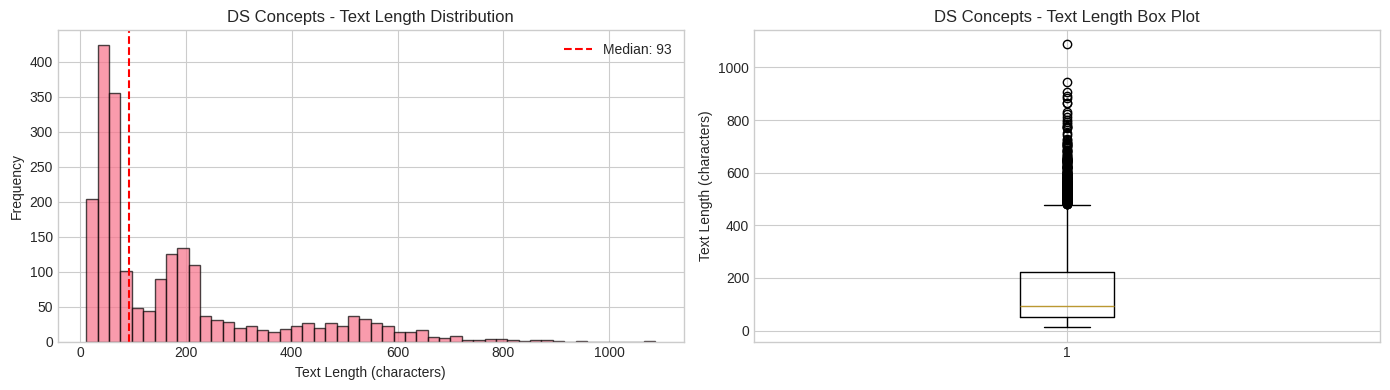


DS Concepts Text Statistics:
   Count: 2,140
   Mean: 178.9
   Median: 93.0
   Min: 12
   Max: 1,087
   Std: 180.2


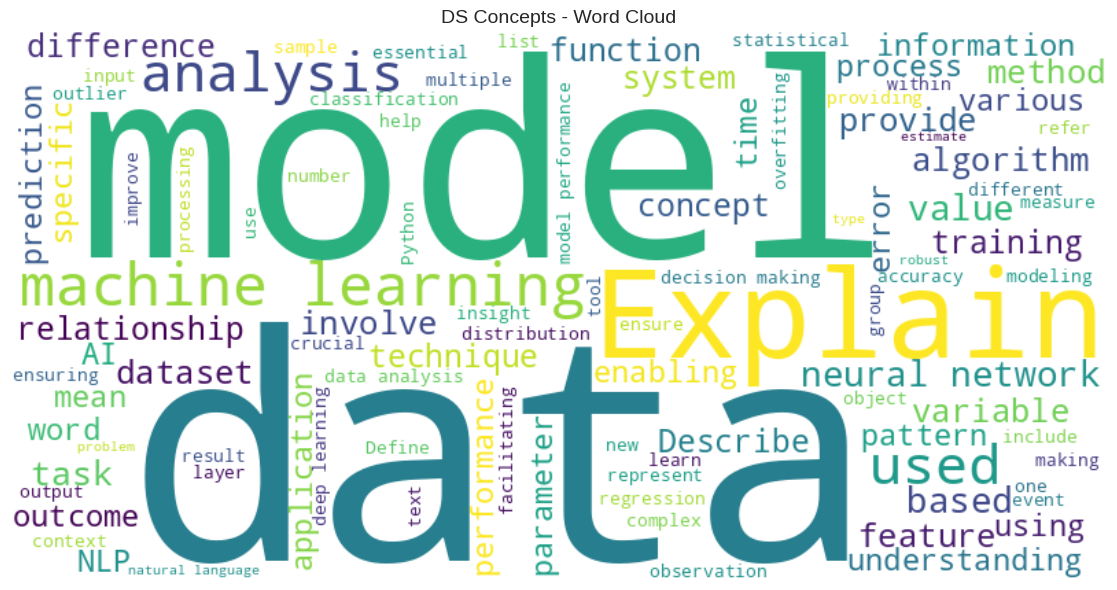

In [ ]:
# EDA for DS Concepts
if "ds_concepts" in all_datasets["theory"]:
    df = all_datasets["theory"]["ds_concepts"]
    print("\n" + "-"*60)
    print("DS Concepts Dataset")
    print("-"*60)
    print(f"\nColumns: {list(df.columns)}")
    print(f"\nData types:\n{df.dtypes}")

    missing_value_analysis(df, "DS Concepts")

    # Identify text columns
    text_cols = [c for c in df.columns if df[c].dtype == 'object']
    if text_cols:
        text_length_stats(df, text_cols, "DS Concepts")
        generate_wordcloud(df, text_cols, "DS Concepts")


------------------------------------------------------------
github_interview Dataset
------------------------------------------------------------
Columns: ['Category', 'Questions', 'Answers']
Shape: (324, 3)

github_interview - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!


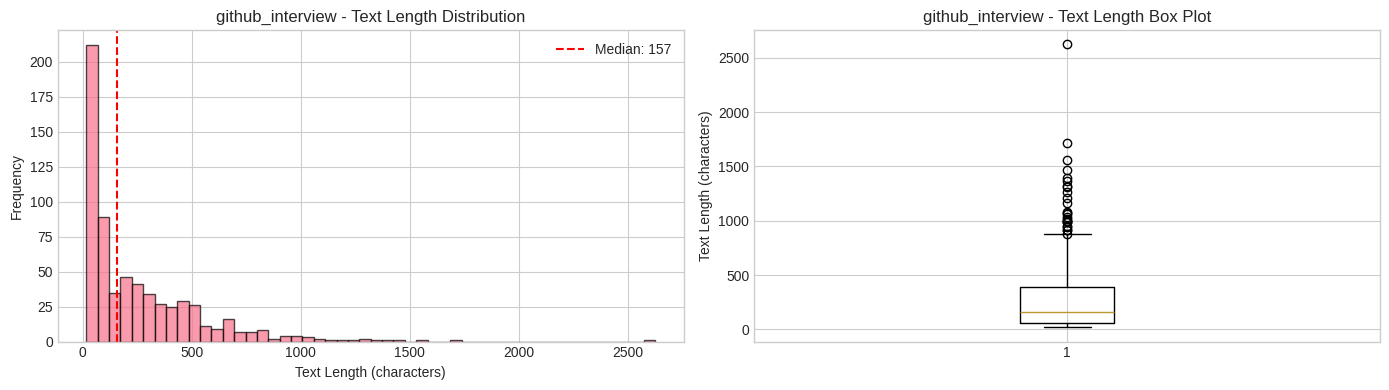


github_interview Text Statistics:
   Count: 648
   Mean: 261.2
   Median: 157.0
   Min: 17
   Max: 2,624
   Std: 287.6

------------------------------------------------------------
treasury Dataset
------------------------------------------------------------
Columns: ['question', 'answer']
Shape: (166, 2)

treasury - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!


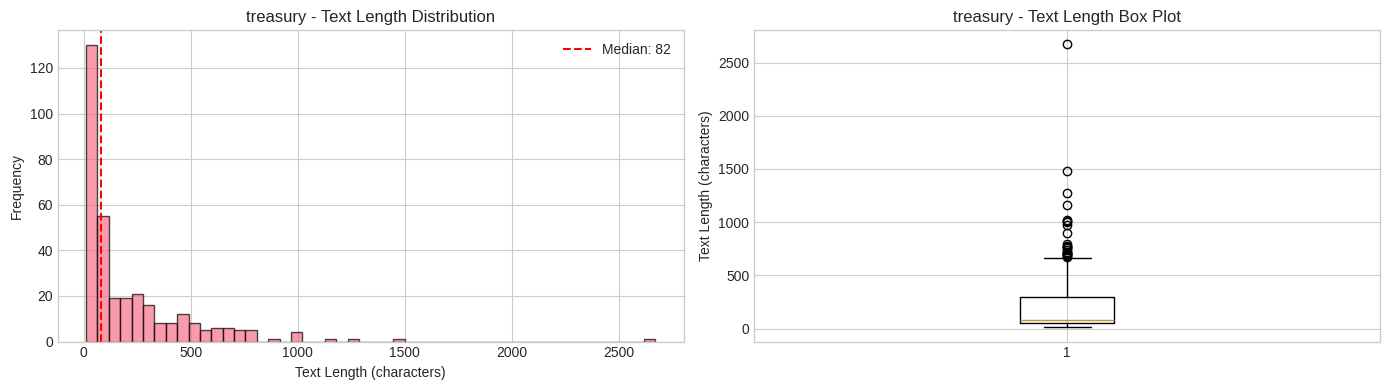


treasury Text Statistics:
   Count: 332
   Mean: 215.8
   Median: 81.5
   Min: 11
   Max: 2,670
   Std: 277.3

------------------------------------------------------------
dsqa Dataset
------------------------------------------------------------
Columns: ['Question', 'Answer']
Shape: (158, 2)

dsqa - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!


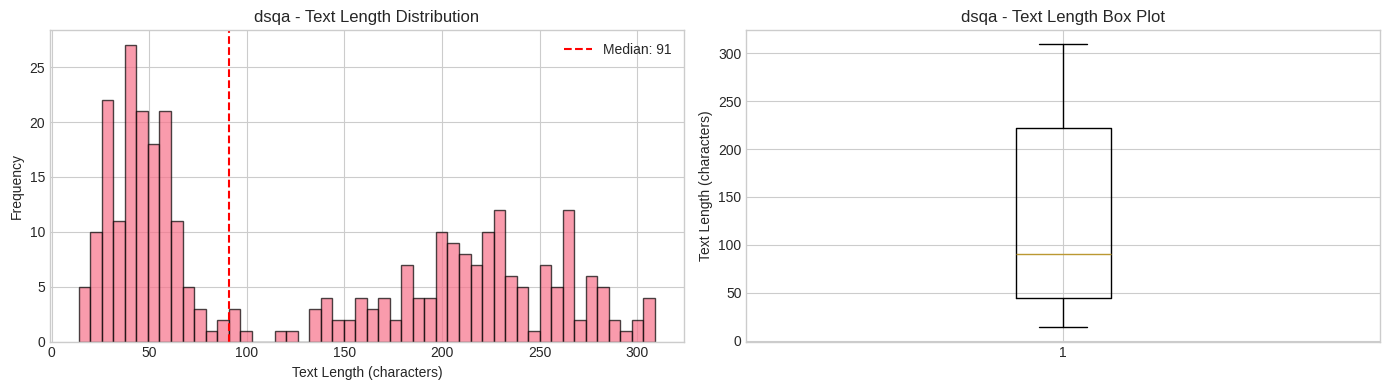


dsqa Text Statistics:
   Count: 316
   Mean: 132.0
   Median: 91.0
   Min: 14
   Max: 309
   Std: 93.3


In [ ]:
# EDA for Interview Q&A datasets
for name in ["github_interview", "treasury", "dsqa"]:
    if name in all_datasets["theory"] and all_datasets["theory"][name] is not None:
        df = all_datasets["theory"][name]
        print("\n" + "-"*60)
        print(f"{name} Dataset")
        print("-"*60)
        print(f"Columns: {list(df.columns)}")
        print(f"Shape: {df.shape}")

        missing_value_analysis(df, name)

        # Look for Q&A columns
        q_cols = [c for c in df.columns if 'question' in c.lower() or 'q' == c.lower()]
        a_cols = [c for c in df.columns if 'answer' in c.lower() or 'a' == c.lower()]
        text_cols = q_cols + a_cols if q_cols or a_cols else [c for c in df.columns if df[c].dtype == 'object'][:2]

        if text_cols:
            text_length_stats(df, text_cols, name)

### EDA: Code Datasets


EDA: CODE DATASETS

------------------------------------------------------------
DS Coder Instruct v2
------------------------------------------------------------
Columns: ['input', 'text', 'instruction', 'output', 'lang', 'dataset', 'nl_ratio', 'mean_ln_len', 'code_len', 'instruction_len', 'topics', 'has_ml', 'has_nn', 'has_wrang', 'has_plt', 'has_comp']
Shape: (17311, 16)

DS Coder - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!


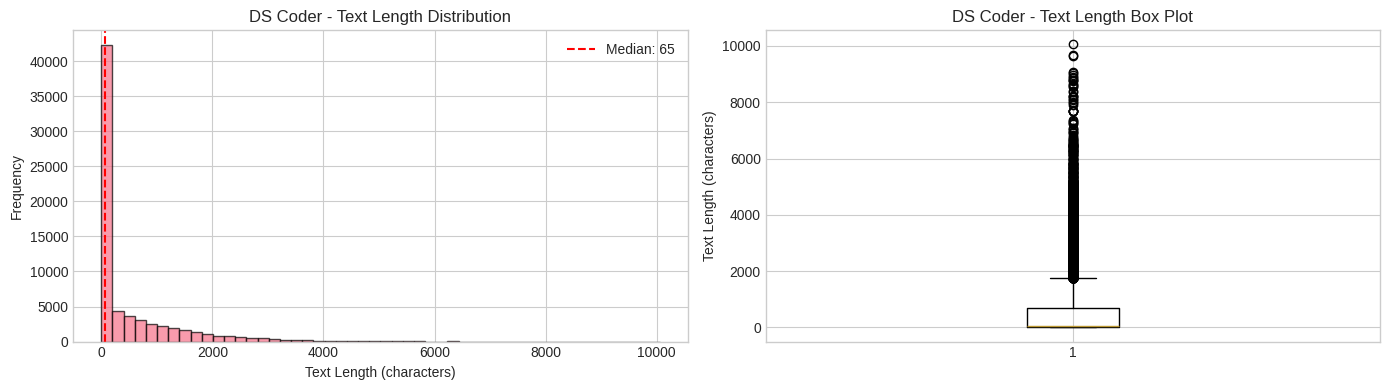


DS Coder Text Statistics:
   Count: 69,244
   Mean: 506.8
   Median: 65.0
   Min: 0
   Max: 10,053
   Std: 864.5


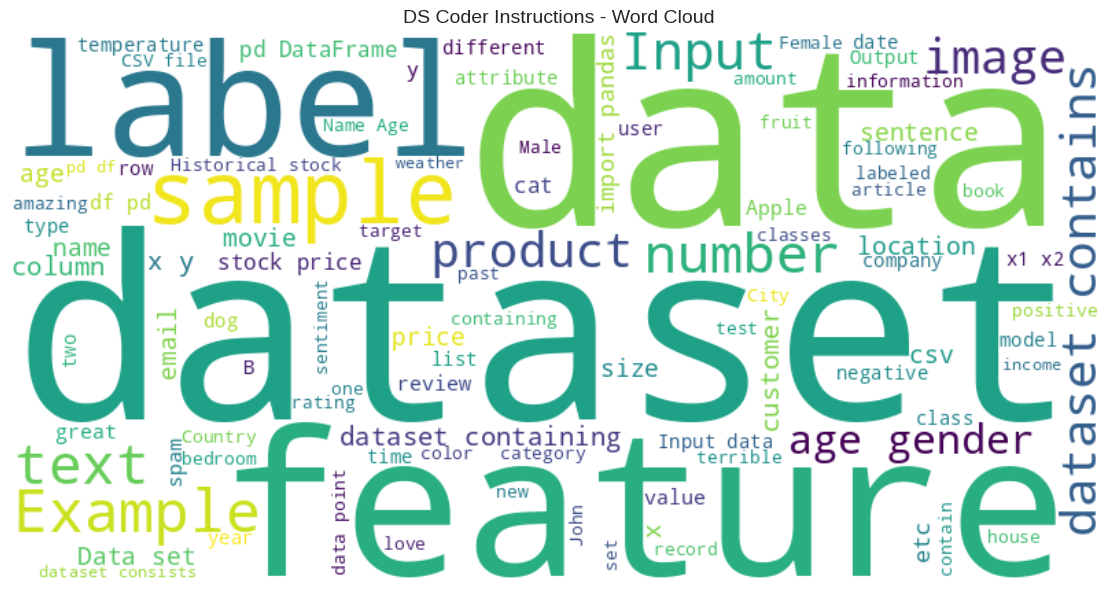

In [ ]:
print("\n" + "="*80)
print("EDA: CODE DATASETS")
print("="*80)

# DS Coder Instruct
if "ds_coder" in all_datasets["code"]:
    df = all_datasets["code"]["ds_coder"]
    print("\n" + "-"*60)
    print("DS Coder Instruct v2")
    print("-"*60)
    print(f"Columns: {list(df.columns)}")
    print(f"Shape: {df.shape}")

    missing_value_analysis(df, "DS Coder")

    # Instruction/Output length analysis
    inst_cols = [c for c in df.columns if 'instruction' in c.lower() or 'input' in c.lower() or 'output' in c.lower()]
    if inst_cols:
        text_length_stats(df, inst_cols, "DS Coder")
        generate_wordcloud(df, inst_cols[:2], "DS Coder Instructions")


------------------------------------------------------------
CodeAlpaca-20k: Raw vs DS Filtered
------------------------------------------------------------


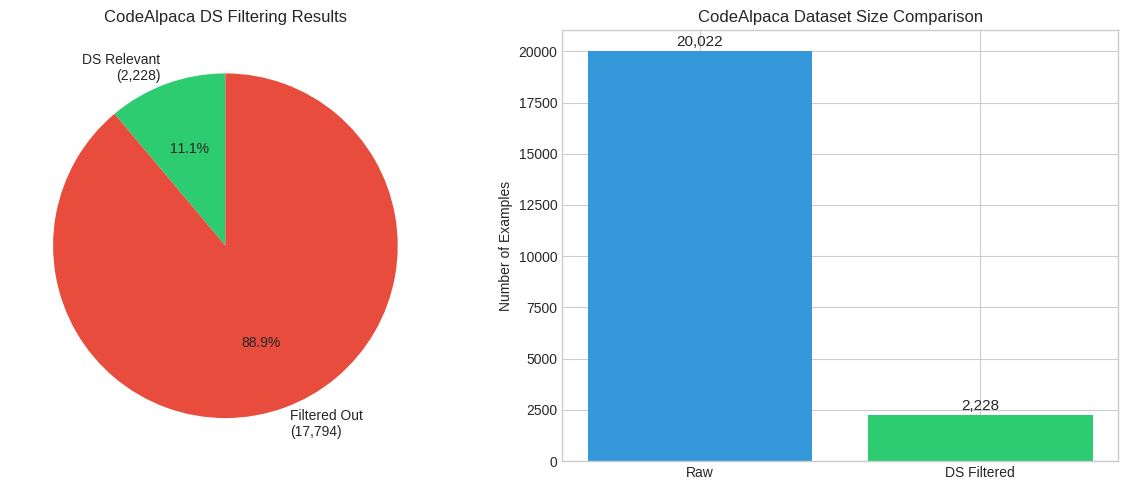


   Raw size: 20,022
   Filtered size: 2,228
   Retention rate: 11.1%


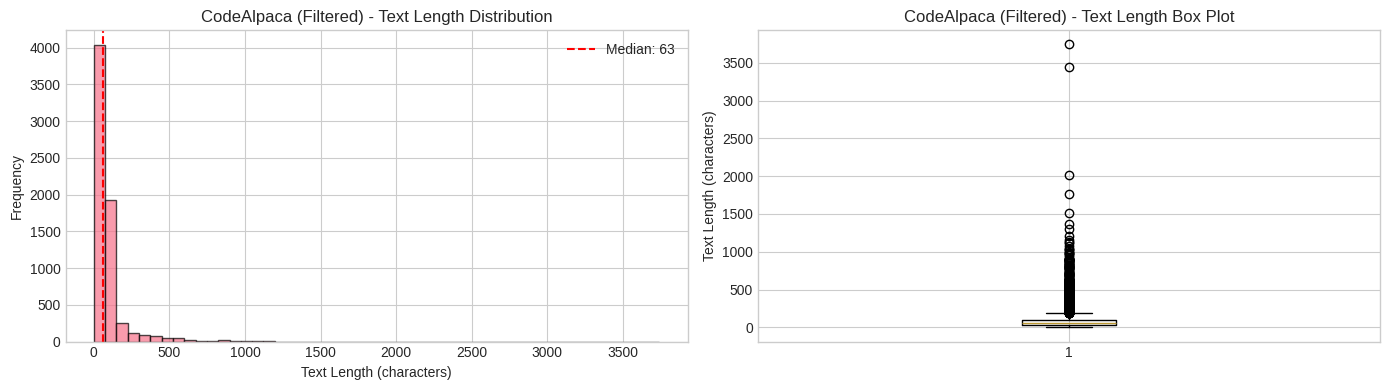


CodeAlpaca (Filtered) Text Statistics:
   Count: 6,684
   Mean: 88.0
   Median: 63.0
   Min: 0
   Max: 3,741
   Std: 140.3


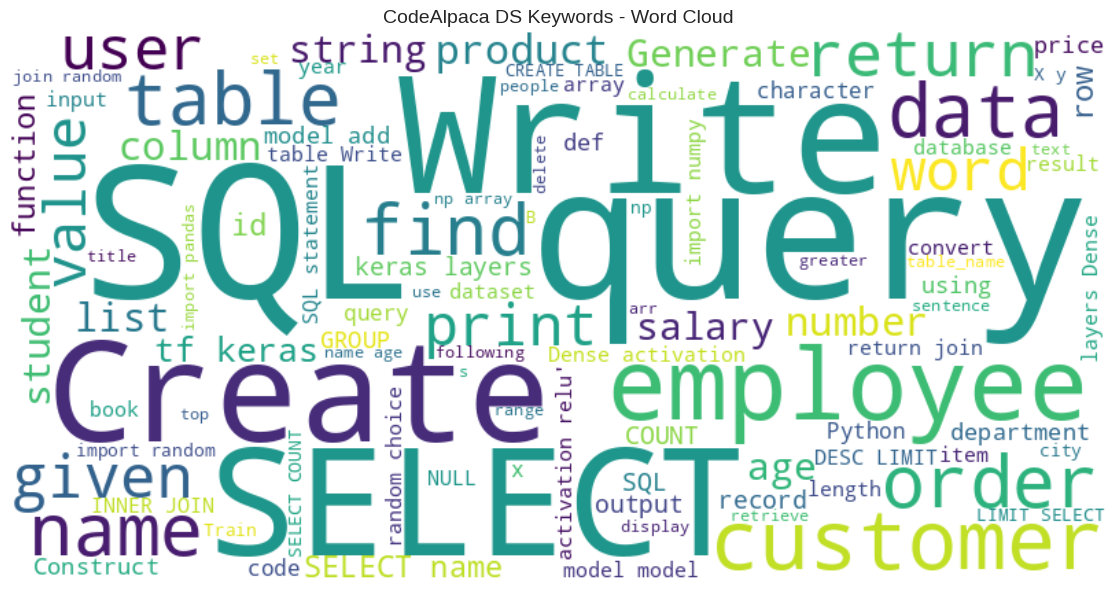

In [ ]:
# CodeAlpaca comparison (raw vs filtered)
if "code_alpaca_raw" in all_datasets["code"] and "code_alpaca_filtered" in all_datasets["code"]:
    raw_df = all_datasets["code"]["code_alpaca_raw"]
    filtered_df = all_datasets["code"]["code_alpaca_filtered"]

    print("\n" + "-"*60)
    print("CodeAlpaca-20k: Raw vs DS Filtered")
    print("-"*60)

    # Filtering effectiveness
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Pie chart: filtering ratio
    sizes = [len(filtered_df), len(raw_df) - len(filtered_df)]
    labels = [f'DS Relevant\n({len(filtered_df):,})', f'Filtered Out\n({len(raw_df) - len(filtered_df):,})']
    colors = ['#2ecc71', '#e74c3c']
    axes[0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
    axes[0].set_title('CodeAlpaca DS Filtering Results')

    # Bar chart comparison
    categories = ['Raw', 'DS Filtered']
    counts = [len(raw_df), len(filtered_df)]
    bars = axes[1].bar(categories, counts, color=['#3498db', '#2ecc71'])
    axes[1].set_ylabel('Number of Examples')
    axes[1].set_title('CodeAlpaca Dataset Size Comparison')
    for bar, count in zip(bars, counts):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                    f'{count:,}', ha='center', va='bottom', fontsize=11)

    plt.tight_layout()
    plt.show()

    print(f"\n   Raw size: {len(raw_df):,}")
    print(f"   Filtered size: {len(filtered_df):,}")
    print(f"   Retention rate: {100*len(filtered_df)/len(raw_df):.1f}%")

    # Text length comparison
    text_length_stats(filtered_df, ['instruction', 'input', 'output'], "CodeAlpaca (Filtered)")
    generate_wordcloud(filtered_df, ['instruction', 'output'], "CodeAlpaca DS Keywords")

### EDA: Math Datasets


EDA: MATH DATASETS


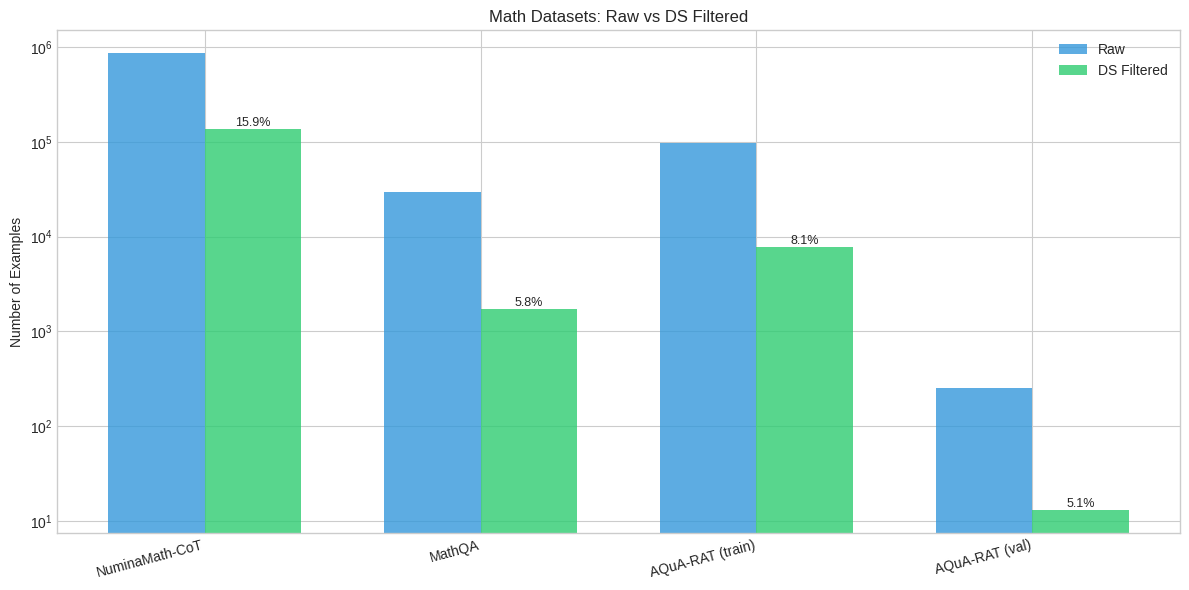


Math Dataset Filtering Summary:
------------------------------------------------------------
Dataset                            Raw     Filtered    Retention
------------------------------------------------------------
NuminaMath-CoT                 859,494      136,435        15.9%
MathQA                          29,837        1,736         5.8%
AQuA-RAT (train)                97,467        7,857         8.1%
AQuA-RAT (val)                     254           13         5.1%


In [ ]:
print("\n" + "="*80)
print("EDA: MATH DATASETS")
print("="*80)

# Overview of filtering effectiveness for all math datasets
math_filter_stats = [
    ('NuminaMath-CoT',
     len(all_datasets["math"].get("numina_raw", [])),
     len(all_datasets["math"].get("numina_filtered", []))),
    ('MathQA',
     len(all_datasets["math"].get("mathqa_raw", [])),
     len(all_datasets["math"].get("mathqa_filtered", []))),
    ('AQuA-RAT (train)',
     len(all_datasets["math"].get("aqua_train_raw", [])),
     len(all_datasets["math"].get("aqua_train_filtered", []))),
    ('AQuA-RAT (val)',
     len(all_datasets["math"].get("aqua_val_raw", [])),
     len(all_datasets["math"].get("aqua_val_filtered", []))),
]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(math_filter_stats))
width = 0.35

raw_counts = [s[1] for s in math_filter_stats]
filtered_counts = [s[2] for s in math_filter_stats]
names = [s[0] for s in math_filter_stats]

bars1 = ax.bar(x - width/2, raw_counts, width, label='Raw', color='#3498db', alpha=0.8)
bars2 = ax.bar(x + width/2, filtered_counts, width, label='DS Filtered', color='#2ecc71', alpha=0.8)

ax.set_ylabel('Number of Examples')
ax.set_title('Math Datasets: Raw vs DS Filtered')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15, ha='right')
ax.legend()
ax.set_yscale('log')

# Add retention rate labels
for i, (raw, filt) in enumerate(zip(raw_counts, filtered_counts)):
    if raw > 0:
        rate = 100 * filt / raw
        ax.annotate(f'{rate:.1f}%', xy=(i + width/2, filt), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Print summary table
print("\nMath Dataset Filtering Summary:")
print("-" * 60)
print(f"{'Dataset':<25} {'Raw':>12} {'Filtered':>12} {'Retention':>12}")
print("-" * 60)
for name, raw, filt in math_filter_stats:
    rate = 100 * filt / raw if raw > 0 else 0
    print(f"{name:<25} {raw:>12,} {filt:>12,} {rate:>11.1f}%")


------------------------------------------------------------
NuminaMath-CoT (DS Filtered)
------------------------------------------------------------
Columns: ['source', 'problem', 'solution', 'messages']

NuminaMath - Missing Value Analysis:


,Column,Missing Count,Missing %


   No missing values!

Source Distribution:
source
cn_k12            57991
olympiads         31352
synthetic_math    23742
synthetic_amc      8339
aops_forum         6952
orca_math          6057
math               1243
amc_aime            648
gsm8k               111
Name: count, dtype: int64


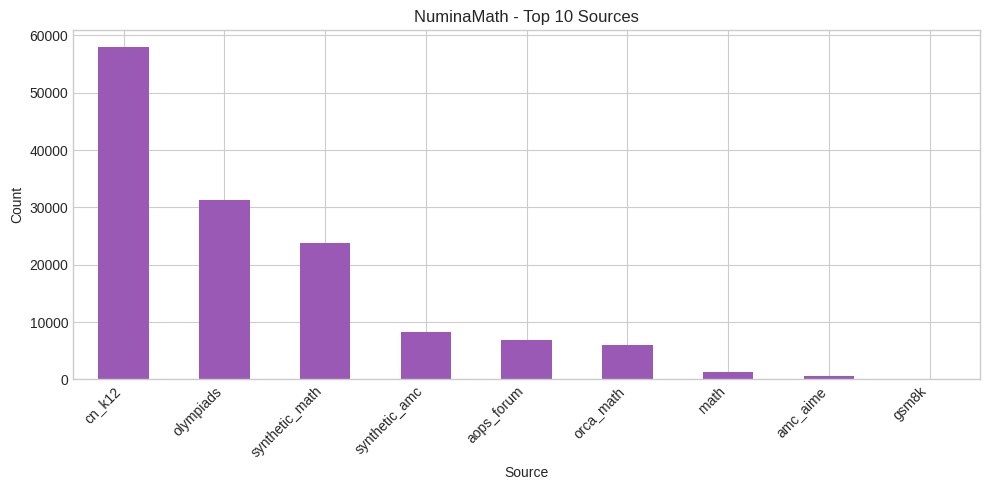

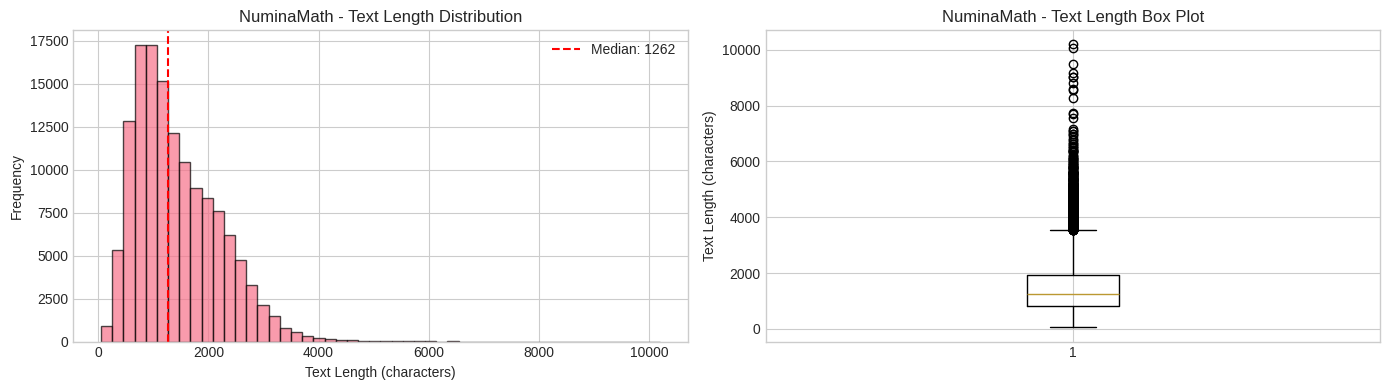


NuminaMath Text Statistics:
   Count: 136,435
   Mean: 1432.0
   Median: 1262.0
   Min: 51
   Max: 10,194
   Std: 770.7


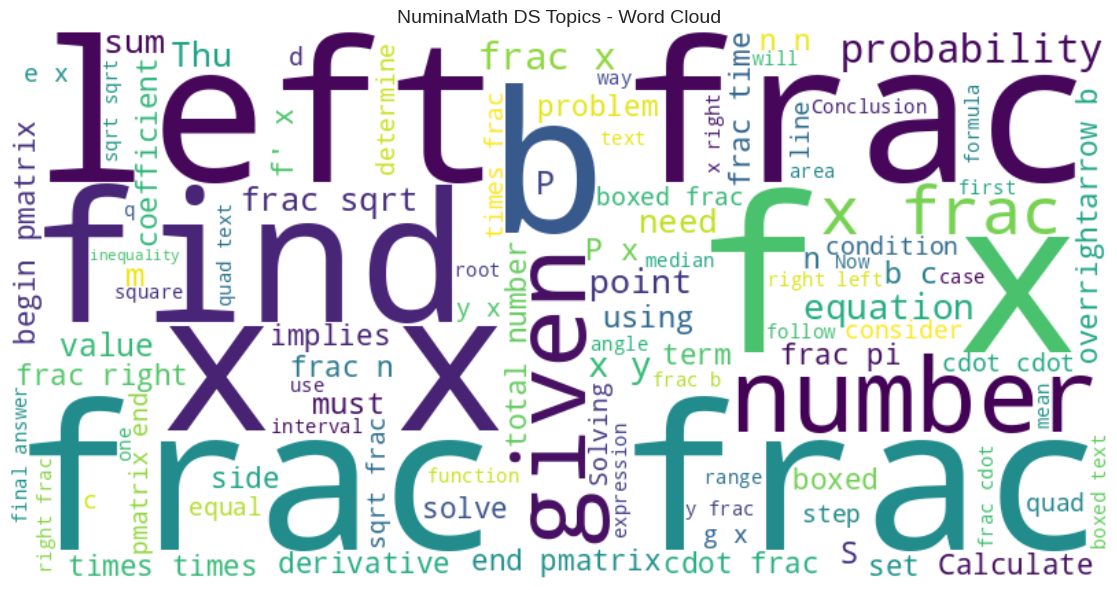

In [ ]:
# Detailed EDA for NuminaMath
if "numina_filtered" in all_datasets["math"]:
    df = all_datasets["math"]["numina_filtered"]
    print("\n" + "-"*60)
    print("NuminaMath-CoT (DS Filtered)")
    print("-"*60)
    print(f"Columns: {list(df.columns)}")

    missing_value_analysis(df, "NuminaMath")

    # Check for source/level distribution if available
    if 'source' in df.columns:
        print("\nSource Distribution:")
        source_counts = df['source'].value_counts().head(10)
        print(source_counts)

        fig, ax = plt.subplots(figsize=(10, 5))
        source_counts.plot(kind='bar', ax=ax, color='#9b59b6')
        ax.set_title('NuminaMath - Top 10 Sources')
        ax.set_xlabel('Source')
        ax.set_ylabel('Count')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    text_length_stats(df, ['question', 'solution'], "NuminaMath")
    generate_wordcloud(df, ['question', 'solution'], "NuminaMath DS Topics")


------------------------------------------------------------
MathQA (DS Filtered)
------------------------------------------------------------

Category Distribution:
category
general        939
probability    450
other          156
physics        101
gain            58
geometry        32
Name: count, dtype: int64


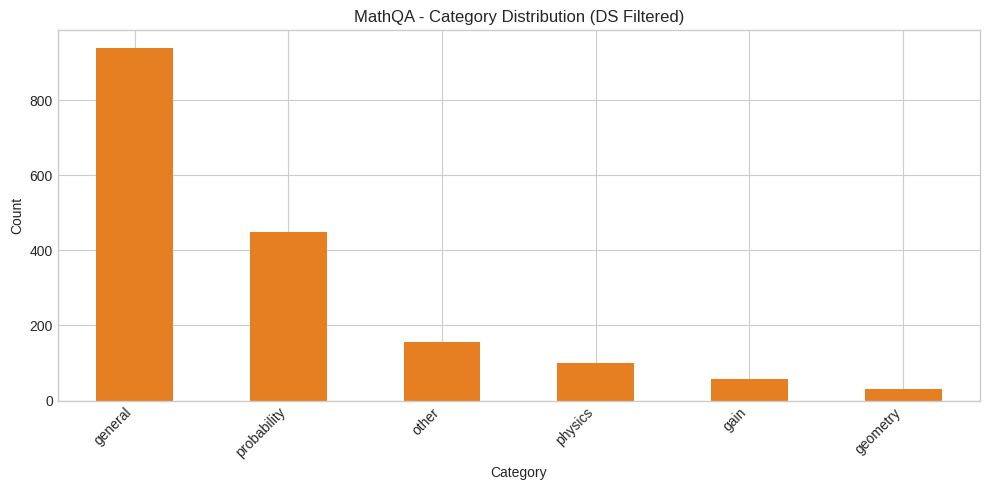

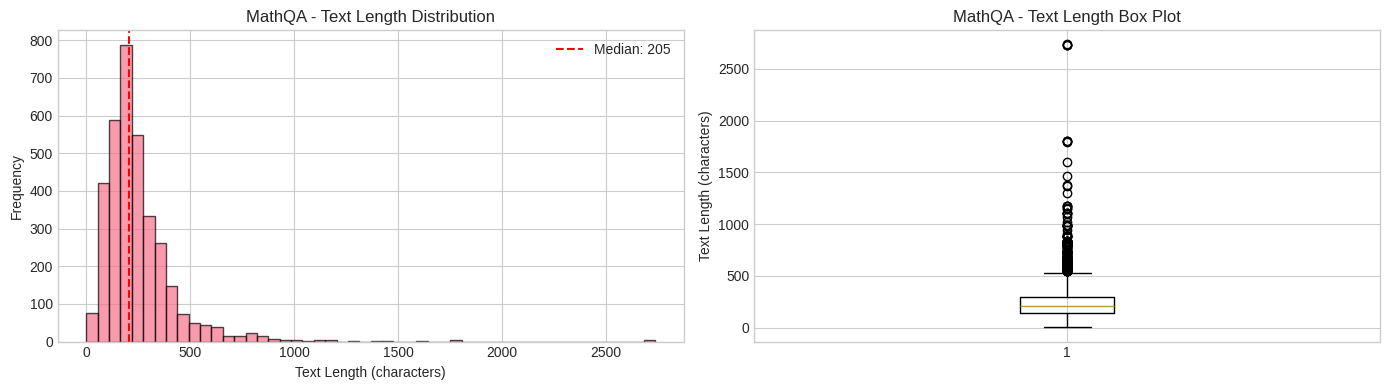


MathQA Text Statistics:
   Count: 3,472
   Mean: 250.2
   Median: 205.0
   Min: 1
   Max: 2,737
   Std: 188.9


In [ ]:
# MathQA category analysis
if "mathqa_filtered" in all_datasets["math"]:
    df = all_datasets["math"]["mathqa_filtered"]
    print("\n" + "-"*60)
    print("MathQA (DS Filtered)")
    print("-"*60)

    if 'category' in df.columns:
        print("\nCategory Distribution:")
        cat_counts = df['category'].value_counts()
        print(cat_counts)

        fig, ax = plt.subplots(figsize=(10, 5))
        cat_counts.plot(kind='bar', ax=ax, color='#e67e22')
        ax.set_title('MathQA - Category Distribution (DS Filtered)')
        ax.set_xlabel('Category')
        ax.set_ylabel('Count')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    text_length_stats(df, ['Problem', 'Rationale'], "MathQA")


------------------------------------------------------------
AQuA-RAT Train (DS Filtered)
------------------------------------------------------------
Columns: ['question', 'options', 'rationale', 'correct']

Correct Answer Distribution:
correct
A    1557
B    1756
C    1851
D    1557
E    1136
Name: count, dtype: int64


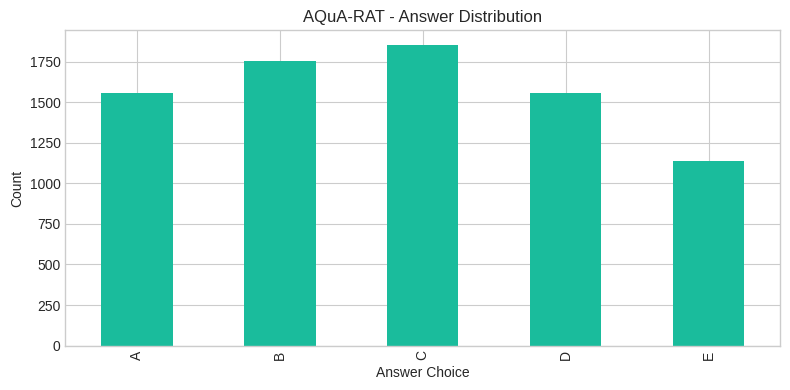

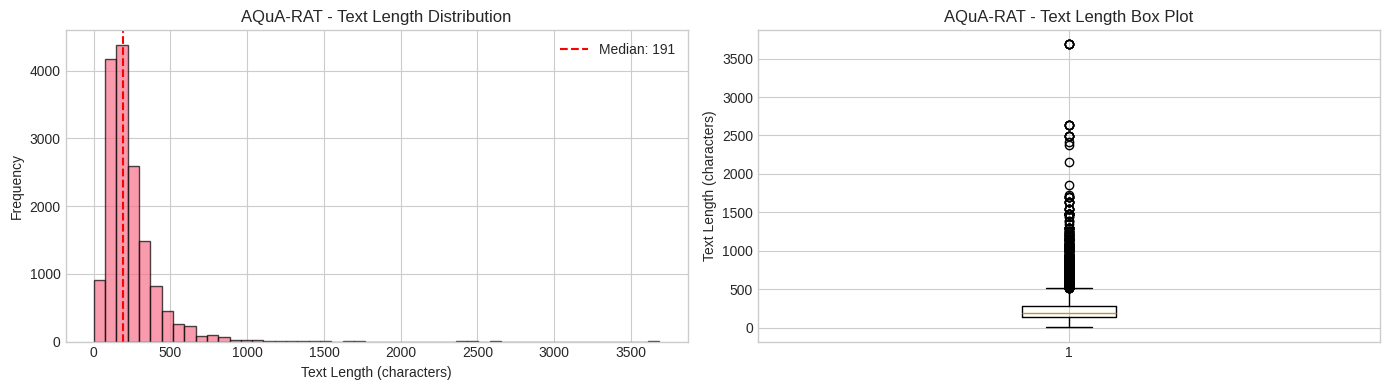


AQuA-RAT Text Statistics:
   Count: 15,714
   Mean: 236.8
   Median: 191.0
   Min: 1
   Max: 3,684
   Std: 190.1


In [ ]:
# AQuA-RAT analysis
if "aqua_train_filtered" in all_datasets["math"]:
    df = all_datasets["math"]["aqua_train_filtered"]
    print("\n" + "-"*60)
    print("AQuA-RAT Train (DS Filtered)")
    print("-"*60)
    print(f"Columns: {list(df.columns)}")

    # Answer distribution
    if 'correct' in df.columns:
        print("\nCorrect Answer Distribution:")
        ans_counts = df['correct'].value_counts().sort_index()
        print(ans_counts)

        fig, ax = plt.subplots(figsize=(8, 4))
        ans_counts.plot(kind='bar', ax=ax, color='#1abc9c')
        ax.set_title('AQuA-RAT - Answer Distribution')
        ax.set_xlabel('Answer Choice')
        ax.set_ylabel('Count')
        plt.tight_layout()
        plt.show()

    text_length_stats(df, ['question', 'rationale'], "AQuA-RAT")

## Final Category Distribution


FINAL DATASET DISTRIBUTION


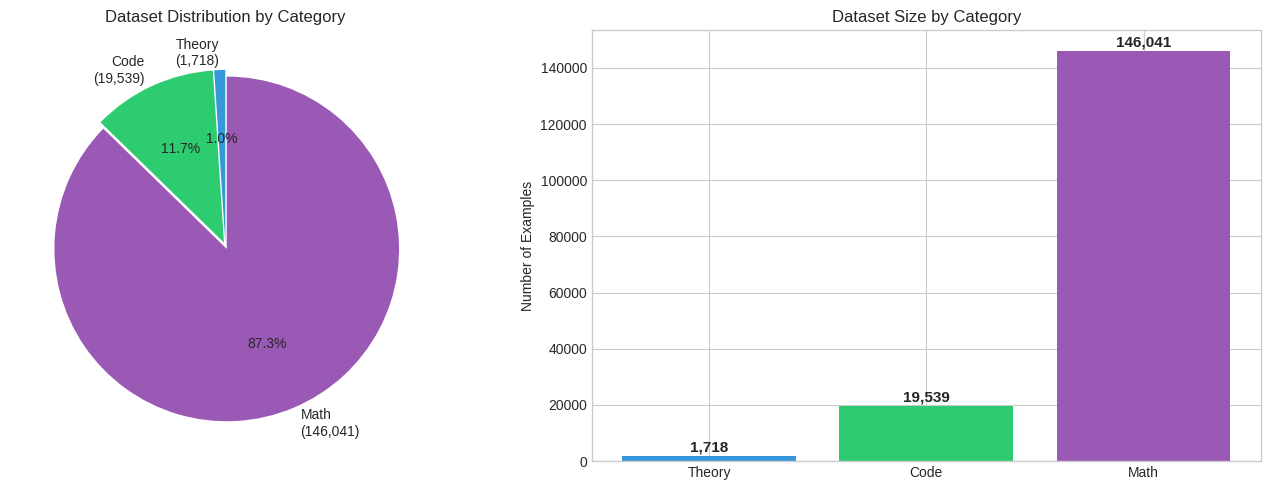


GRAND TOTAL FOR TRAINING: 167,298

   Theory: 1,718 (1.0%)
   Code:   19,539 (11.7%)
   Math:   146,041 (87.3%)


In [ ]:
# Final visualization: Category distribution
print("\n" + "="*80)
print("FINAL DATASET DISTRIBUTION")
print("="*80)

# Calculate totals for training
theory_total = sum([len(df) for df in all_datasets["theory"].values() if df is not None])
code_total = (len(all_datasets["code"].get("ds_coder", [])) +
              len(all_datasets["code"].get("code_alpaca_filtered", [])))
math_total = (len(all_datasets["math"].get("numina_filtered", [])) +
              len(all_datasets["math"].get("mathqa_filtered", [])) +
              len(all_datasets["math"].get("aqua_train_filtered", [])) +
              len(all_datasets["math"].get("aqua_val_filtered", [])))

categories = ['Theory', 'Code', 'Math']
totals = [theory_total, code_total, math_total]
colors = ['#3498db', '#2ecc71', '#9b59b6']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
axes[0].pie(totals, labels=[f"{c}\n({t:,})" for c, t in zip(categories, totals)],
           colors=colors, autopct='%1.1f%%', startangle=90, explode=(0.02, 0.02, 0.02))
axes[0].set_title('Dataset Distribution by Category', fontsize=12)

# Bar chart
bars = axes[1].bar(categories, totals, color=colors)
axes[1].set_ylabel('Number of Examples')
axes[1].set_title('Dataset Size by Category', fontsize=12)
for bar, total in zip(bars, totals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                f'{total:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

grand_total = sum(totals)
print(f"\nGRAND TOTAL FOR TRAINING: {grand_total:,}")
print(f"\n   Theory: {theory_total:,} ({100*theory_total/grand_total:.1f}%)")
print(f"   Code:   {code_total:,} ({100*code_total/grand_total:.1f}%)")
print(f"   Math:   {math_total:,} ({100*math_total/grand_total:.1f}%)")

In [ ]:
# Final summary export
summary_data = {
    "timestamp": pd.Timestamp.now().isoformat(),
    "gcp_project": PROJECT_ID,
    "raw_bucket": RAW_BUCKET,
    "theory_datasets": {k: len(v) for k, v in all_datasets["theory"].items() if v is not None},
    "code_datasets": {k: len(v) for k, v in all_datasets["code"].items() if v is not None},
    "math_datasets": {k: len(v) for k, v in all_datasets["math"].items() if v is not None},
    "totals": {
        "theory": theory_total,
        "code": code_total,
        "math": math_total,
        "grand_total": grand_total
    }
}

with open(f"{DATA_DIR}/phase1_summary.json", "w") as f:
    json.dump(summary_data, f, indent=2)

print("Summary saved to:", f"{DATA_DIR}/phase1_summary.json")

Summary saved to: ./data/phase1_summary.json
